# EP2 — Reconocimiento de letras ASL mediante una CNN

## Etapas 1–3: datos, diseño y entrenamiento de CNN

**Asignatura:** Técnicas Avanzadas de Machine Learning I (TLY1102)  
**Dataset:** Sign Language MNIST (Kaggle)  
**Variante:** clasificación multiclase de las letras A, E y S.  
**Objetivo:** preparar datos reproducibles para entrenar una red neuronal convolucional (CNN), conservando la MLP de la EP1 como referencia.

### Problema
Las letras A, E y S tienen configuraciones de mano visualmente parecidas. Se pretende distinguirlas a partir de imágenes de 28 × 28 píxeles en escala de grises. Esto es un experimento académico sobre **ASL estadounidense**, no un traductor completo ni un sistema validado para la lengua de señas chilena (LSCh).

### Criterios de éxito propuestos, heredados de EP1
- Accuracy en test mayor a 90 %.
- F1 macro en test mayor a 0,85.
- Recall mayor a 0,80 para cada clase.
- Registrar y explicar las confusiones entre letras, no solo una puntuación global.

Las etapas 1–3 **preparan, diseñan y entrenan dos CNN** al ejecutar el notebook en un entorno con TensorFlow. El test oficial queda reservado para la etapa de evaluación final. Se reserva el test original sin utilizarlo para ajustar decisiones del modelo.

In [ ]:
!git clone --branch develop https://github.com/BenjaDaDuoc/asl-cnn-aes.git /content/asl-cnn-aes

fatal: destination path '/content/asl-cnn-aes' already exists and is not an empty directory.


## 1. Importaciones, semilla y rutas de datos

El notebook funciona tanto si Jupyter se abre desde la raíz del repositorio como si se abre desde la carpeta notebooks. Los archivos CSV originales ya están almacenados en data/.

In [ ]:
from pathlib import Path
import hashlib
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

TAMANO_IMAGEN = (28, 28)
CANALES = 1
LETRAS_OBJETIVO = ("A", "E", "S")
ETIQUETAS_ORIGINALES = {"A": 0, "E": 4, "S": 18}
ETIQUETA_A_INDICE = {0: 0, 4: 1, 18: 2}
INDICE_A_LETRA = {0: "A", 1: "E", 2: "S"}
N_CLASES = len(LETRAS_OBJETIVO)

CANDIDATAS_DATA = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path("/content/asl-cnn-aes/data"),
]

DATA_DIR = next(
    (ruta for ruta in CANDIDATAS_DATA
     if (ruta / "sign_mnist_train.csv").is_file()
     and (ruta / "sign_mnist_test.csv").is_file()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontraron sign_mnist_train.csv y sign_mnist_test.csv. "
        "Ejecuta Jupyter desde la raíz o notebooks/ del repositorio, "
        "o clona asl-cnn-aes en /content/ si usas Google Colab."
    )

sns.set_theme(style="whitegrid")
print("Directorio de datos:", DATA_DIR.resolve())
print("Semilla:", SEED)

Directorio de datos: /content/asl-cnn-aes/data
Semilla: 42


## 2. Inspección del dataset completo

Cada fila del CSV es una imagen: una columna label y 784 columnas pixel1…pixel784. Los píxeles originales están en el rango 0–255. Las 24 clases corresponden a las letras A–Y, sin J, y tampoco se incluye Z porque ambas requieren movimiento en ASL.

Comprobaremos la estructura real de los archivos antes de asumir tamaños, formatos y calidad de los datos.

In [ ]:
df_train_full = pd.read_csv(DATA_DIR / "sign_mnist_train.csv")
df_test_full = pd.read_csv(DATA_DIR / "sign_mnist_test.csv")

COLUMNAS_PIXELES = [f"pixel{i}" for i in range(1, 785)]
COLUMNAS_ESPERADAS = ["label", *COLUMNAS_PIXELES]
for nombre, df in [("Entrenamiento", df_train_full), ("Prueba", df_test_full)]:
    if df.columns.tolist() != COLUMNAS_ESPERADAS:
        raise ValueError(f"{nombre}: columnas inesperadas. Revisar formato del CSV.")
    if df.isna().to_numpy().any():
        raise ValueError(f"{nombre}: hay valores nulos.")
    minimo = df[COLUMNAS_PIXELES].to_numpy().min()
    maximo = df[COLUMNAS_PIXELES].to_numpy().max()
    if not (0 <= minimo <= maximo <= 255):
        raise ValueError(f"{nombre}: valores de píxeles fuera del rango 0–255.")
    print(
        f"{nombre}: {len(df):,} imágenes | {df.shape[1]} columnas "
        f"| clases={df['label'].nunique()} | píxeles [{minimo}, {maximo}] "
        f"| filas idénticas repetidas={df.duplicated().sum()}"
    )

if len(df_train_full) != 27455 or len(df_test_full) != 7172:
    print("Advertencia: los tamaños no coinciden con la versión del dataset usada en EP1.")

Entrenamiento: 27,455 imágenes | 785 columnas | clases=24 | píxeles [0, 255] | filas idénticas repetidas=0
Prueba: 7,172 imágenes | 785 columnas | clases=24 | píxeles [0, 255] | filas idénticas repetidas=0


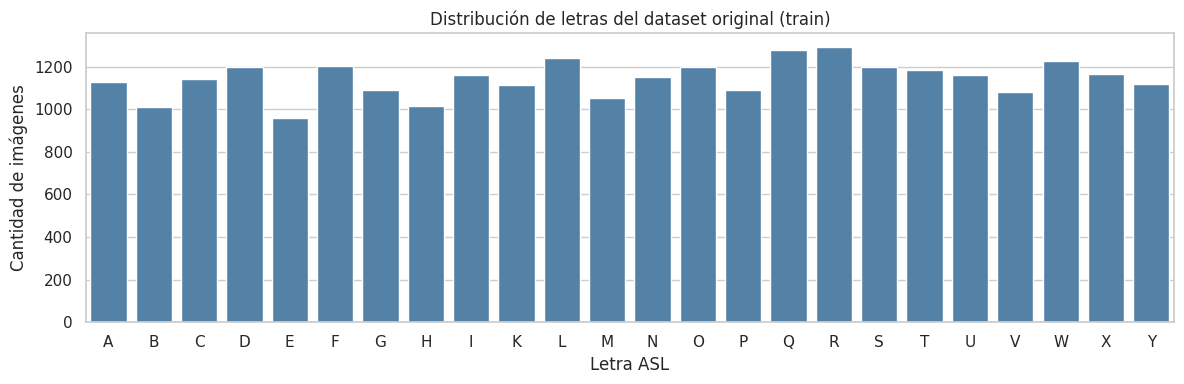

In [ ]:
# Mostrar distribución del conjunto de entrenamiento original (24 clases).
etiqueta_a_letra = {i: chr(ord("A") + i) for i in range(25) if i != 9}
conteo_completo = (
    df_train_full["label"].value_counts().sort_index().rename_axis("label")
    .reset_index(name="cantidad")
)
conteo_completo["letra"] = conteo_completo["label"].map(etiqueta_a_letra)
if conteo_completo["letra"].isna().any():
    raise ValueError("Se encontraron etiquetas sin correspondencia en el alfabeto ASL.")

plt.figure(figsize=(12, 4))
sns.barplot(data=conteo_completo, x="letra", y="cantidad", color="steelblue")
plt.title("Distribución de letras del dataset original (train)")
plt.xlabel("Letra ASL")
plt.ylabel("Cantidad de imágenes")
plt.tight_layout()
plt.show()

## 3. Variante A / E / S y análisis exploratorio

Elegimos tres señas estáticas con similitudes geométricas. La selección no demuestra por sí sola que sean las tres clases más difíciles del dataset; esa afirmación requeriría un experimento adicional. Para la EP2 mantenemos la misma variante de la EP1 para poder comparar modelos.

Se filtran las etiquetas originales 0 (A), 4 (E) y 18 (S). Las nuevas etiquetas serán 0, 1 y 2.

In [ ]:
def filtrar_clases(df: pd.DataFrame) -> pd.DataFrame:
    """Selecciona A/E/S sin modificar el dataset original."""
    filtrado = df.loc[df["label"].isin(ETIQUETA_A_INDICE)].copy()
    filtrado["clase"] = filtrado["label"].map(ETIQUETA_A_INDICE).astype("int64")
    return filtrado

df_train_aes = filtrar_clases(df_train_full)
df_test_aes = filtrar_clases(df_test_full)

resumen_clases = pd.DataFrame({
    "letra": list(LETRAS_OBJETIVO),
    "label_original": [ETIQUETAS_ORIGINALES[c] for c in LETRAS_OBJETIVO],
    "label_nuevo": list(range(N_CLASES)),
    "train_original": [
        int((df_train_aes["label"] == ETIQUETAS_ORIGINALES[c]).sum())
        for c in LETRAS_OBJETIVO
    ],
    "test_original": [
        int((df_test_aes["label"] == ETIQUETAS_ORIGINALES[c]).sum())
        for c in LETRAS_OBJETIVO
    ],
})
display(resumen_clases)
print("Total de imágenes A/E/S:", len(df_train_aes) + len(df_test_aes))

,letra,label_original,label_nuevo,train_original,test_original
0,A,0,0,1126,331
1,E,4,1,957,498
2,S,18,2,1199,246


Total de imágenes A/E/S: 4357


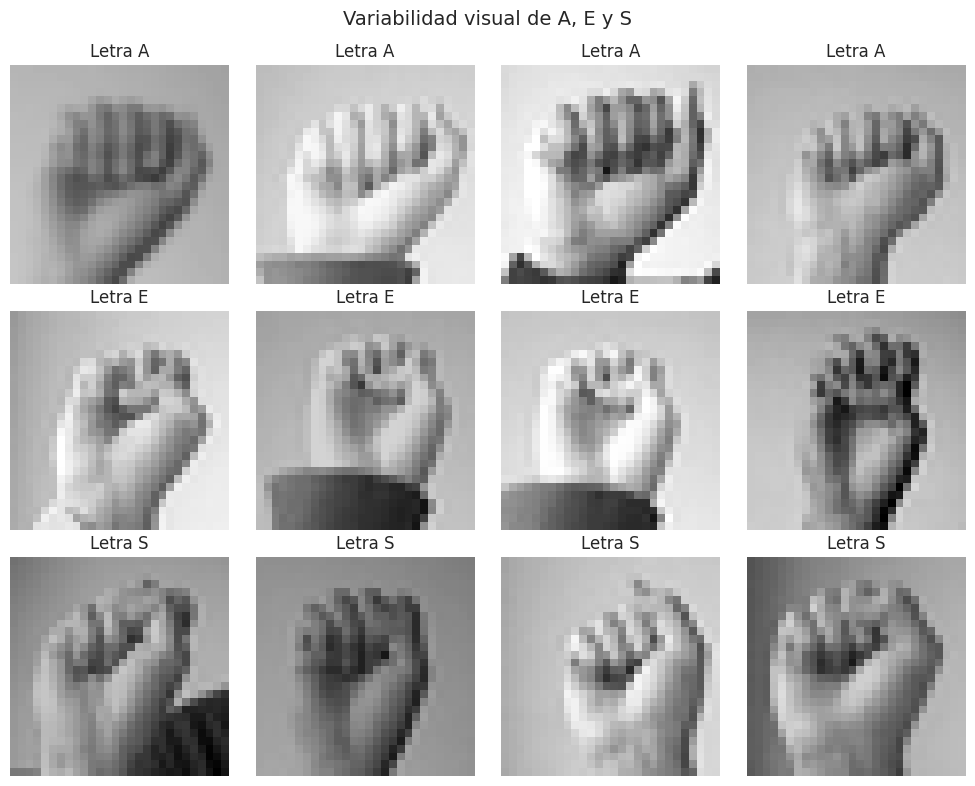

In [ ]:
# Visualización reproducible de ejemplos de cada clase.
fig, ejes = plt.subplots(N_CLASES, 4, figsize=(10, 8))
for fila, letra in enumerate(LETRAS_OBJETIVO):
    muestra = df_train_aes.loc[
        df_train_aes["label"] == ETIQUETAS_ORIGINALES[letra]
    ].sample(n=4, random_state=SEED)
    for columna, (_, registro) in enumerate(muestra.iterrows()):
        imagen = registro[COLUMNAS_PIXELES].to_numpy(dtype=np.uint8).reshape(TAMANO_IMAGEN)
        ejes[fila, columna].imshow(imagen, cmap="gray", vmin=0, vmax=255)
        ejes[fila, columna].set_title(f"Letra {letra}")
        ejes[fila, columna].axis("off")
fig.suptitle("Variabilidad visual de A, E y S", fontsize=14)
plt.tight_layout()
plt.show()

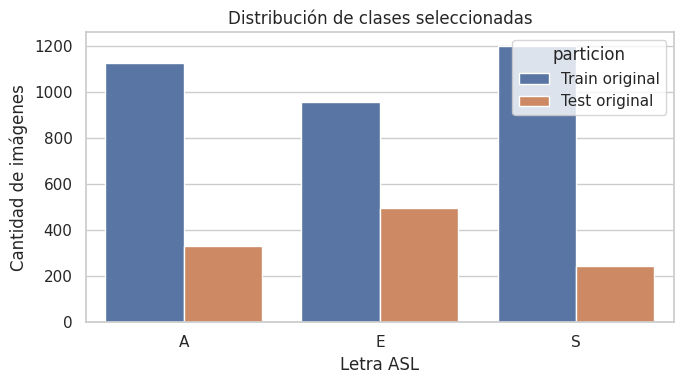

In [ ]:
# Comparación del número de ejemplos disponibles para cada letra.
resumen_largo = resumen_clases.melt(
    id_vars=["letra"], value_vars=["train_original", "test_original"],
    var_name="particion", value_name="imagenes"
)
resumen_largo["particion"] = resumen_largo["particion"].map({
    "train_original": "Train original", "test_original": "Test original"
})
plt.figure(figsize=(7, 4))
sns.barplot(data=resumen_largo, x="letra", y="imagenes", hue="particion")
plt.title("Distribución de clases seleccionadas")
plt.ylabel("Cantidad de imágenes")
plt.xlabel("Letra ASL")
plt.tight_layout()
plt.show()

## 4. Separación, normalización y forma de entrada para CNN

Conservamos el test original aparte (1.075 imágenes A/E/S). Dividimos únicamente el train original, de forma estratificada, en 80 % entrenamiento y 20 % validación, con semilla 42. Este es el mismo criterio de partición usado en EP1 y permite replicar el experimento.

- La MLP de EP1 recibe vectores (784,).
- La CNN recibirá tensores (28, 28, 1), conservando el vecindario espacial entre píxeles.
- Normalizamos dividiendo los valores de intensidad por 255, sin ajustar parámetros utilizando test.
- Prepararemos también etiquetas one-hot, compatibles con una salida softmax y categorical_crossentropy.

**Precaución:** Sign Language MNIST incluye variaciones derivadas de fotografías de origen. Una división aleatoria estratificada puede repartir imágenes casi idénticas entre entrenamiento y validación. La auditoría de coincidencias exactas no detecta todas las casi duplicadas. Antes de interpretar la validación como evidencia fuerte de generalización, conviene definir grupos de imágenes de origen si pueden reconstruirse y, para una comparación más rigurosa, volver a entrenar ambos modelos bajo el mismo protocolo.

In [ ]:
# Convertir solo las columnas de píxeles, sin introducir las etiquetas en X.
X_train_full_plano = (
    df_train_aes[COLUMNAS_PIXELES].to_numpy(dtype=np.float32) / 255.0
)
y_train_full = df_train_aes["clase"].to_numpy(dtype=np.int64)

X_test_plano = df_test_aes[COLUMNAS_PIXELES].to_numpy(dtype=np.float32) / 255.0
y_test = df_test_aes["clase"].to_numpy(dtype=np.int64)

X_train_plano, X_val_plano, y_train, y_val = train_test_split(
    X_train_full_plano,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=SEED,
)

# Dimensión final de entrada: (n_imagenes, 28, 28, 1).
X_train = X_train_plano.reshape(-1, *TAMANO_IMAGEN, CANALES)
X_val = X_val_plano.reshape(-1, *TAMANO_IMAGEN, CANALES)
X_test = X_test_plano.reshape(-1, *TAMANO_IMAGEN, CANALES)

# One-hot para entrenar después una CNN con categorical_crossentropy.
y_train_onehot = np.eye(N_CLASES, dtype=np.float32)[y_train]
y_val_onehot = np.eye(N_CLASES, dtype=np.float32)[y_val]
y_test_onehot = np.eye(N_CLASES, dtype=np.float32)[y_test]

for nombre, x, y, oh in [
    ("Entrenamiento", X_train, y_train, y_train_onehot),
    ("Validación", X_val, y_val, y_val_onehot),
    ("Prueba", X_test, y_test, y_test_onehot),
]:
    print(f"{nombre}: X={x.shape}, y={y.shape}, one-hot={oh.shape}")
    print("  clases:", {INDICE_A_LETRA[i]: int((y == i).sum()) for i in range(N_CLASES)})

Entrenamiento: X=(2625, 28, 28, 1), y=(2625,), one-hot=(2625, 3)
  clases: {'A': 901, 'E': 765, 'S': 959}
Validación: X=(657, 28, 28, 1), y=(657,), one-hot=(657, 3)
  clases: {'A': 225, 'E': 192, 'S': 240}
Prueba: X=(1075, 28, 28, 1), y=(1075,), one-hot=(1075, 3)
  clases: {'A': 331, 'E': 498, 'S': 246}


In [ ]:
# Pruebas automáticas mínimas del preprocesamiento.
assert X_train.shape == (2625, 28, 28, 1)
assert X_val.shape == (657, 28, 28, 1)
assert X_test.shape == (1075, 28, 28, 1)
assert X_train.dtype == X_val.dtype == X_test.dtype == np.float32
assert 0.0 <= X_train.min() <= X_train.max() <= 1.0
assert 0.0 <= X_val.min() <= X_val.max() <= 1.0
assert 0.0 <= X_test.min() <= X_test.max() <= 1.0
assert all(np.isfinite(x).all() for x in [X_train, X_val, X_test])
assert all(np.allclose(y.sum(axis=1), 1) for y in
           [y_train_onehot, y_val_onehot, y_test_onehot])
assert np.array_equal(np.unique(y_train), [0, 1, 2])
assert np.array_equal(np.unique(y_val), [0, 1, 2])
assert np.array_equal(np.unique(y_test), [0, 1, 2])
print("Comprobaciones de forma, tipo, normalización y etiquetas: OK.")

Comprobaciones de forma, tipo, normalización y etiquetas: OK.


## 5. Auditoría preliminar de duplicados entre particiones

Buscamos coincidencias **exactas** entre imágenes de entrenamiento, validación y test. Esta comprobación ayuda a detectar fallas evidentes, pero **cero coincidencias exactas no implica ausencia de leakage**: variaciones por rotación, recorte o brillo pueden seguir siendo casi idénticas. Tampoco se usa el test para elegir hiperparámetros.

In [ ]:
def huellas_exactas(x: np.ndarray) -> set[bytes]:
    """Huella por imagen: solo detecta píxeles exactamente iguales."""
    return {
        hashlib.blake2b(imagen.tobytes(), digest_size=16).digest()
        for imagen in x
    }

h_train = huellas_exactas(X_train)
h_val = huellas_exactas(X_val)
h_test = huellas_exactas(X_test)

coinciden_train_val = len(h_train & h_val)
coinciden_train_test = len(h_train & h_test)
coinciden_val_test = len(h_val & h_test)
print("Coincidencias exactas entre train y validación:", coinciden_train_val)
print("Coincidencias exactas entre train y test:", coinciden_train_test)
print("Coincidencias exactas entre validación y test:", coinciden_val_test)
if coinciden_train_val:
    print("Advertencia: hay imágenes idénticas entre entrenamiento y validación.")
print("Nota: falta verificar similitud de imágenes aumentadas; esta auditoría es parcial.")

Coincidencias exactas entre train y validación: 0
Coincidencias exactas entre train y test: 0
Coincidencias exactas entre validación y test: 0
Nota: falta verificar similitud de imágenes aumentadas; esta auditoría es parcial.


## 6. Resultado de la etapa 1 y siguiente etapa

Los tensores X_train, X_val y X_test (28 × 28 × 1) y sus etiquetas están preparados para conectar una CNN. Se conservan los CSV y el notebook MLP originales, sin sobrescribirlos.

**Decisión metodológica:** utilizar el conjunto test original solamente en la evaluación final. Reportar las limitaciones de validación por posibles variantes de fotografías originales; en la comparación MLP/CNN, explicitar que los modelos deben usar las mismas clases, particiones, métricas y equipo de entrenamiento, y que se deberá volver a medir el tiempo de entrenamiento de la MLP de manera comparable.

**Continuación:** la etapa 2 (a continuación) construye y justifica dos CNN antes de entrenarlas. La etapa 3 entrenará y comparará las curvas de aprendizaje; las métricas de test y Feature Maps vendrán después. No se afirma ninguna mejora de CNN hasta medirla.

---
## 7. Etapa 2 — Diseño de una Red Neuronal Convolucional (CNN)

La red recibirá imágenes de **28 × 28 × 1** (alto × ancho × canales), sin aplanarlas antes de las convoluciones.

**Flujo de la arquitectura**

1. `Conv2D` de 3×3, padding `same`, activación ReLU: detecta patrones locales (bordes, dedos y contornos) sin cambiar las dimensiones espaciales.
2. `MaxPooling2D(2×2)`: reduce a la mitad alto y ancho, disminuyendo cálculos y reteniendo las activaciones más fuertes de cada región.
3. Segunda `Conv2D` de 3×3 + `MaxPooling2D(2×2)`: aprende combinaciones de rasgos más complejos.
4. `Flatten` transforma los mapas resultantes (7×7×filtros) en un vector, ahora sí, para la clasificación.
5. `Dense(64, relu)` combina los rasgos; `Dense(3, softmax)` entrega probabilidades para A, E y S.

**Experimento de arquitectura:** se proponen dos configuraciones **iguales excepto por la cantidad de filtros**. Mantener el tamaño de kernel, la cantidad de capas, las neuronas densas y el learning rate permite evaluar el efecto del número de filtros. No se elige la mejor por el test: eso se hará usando únicamente validación.

La MLP anterior, por el contrario, recibe los 784 valores planos directamente, sin filtros espaciales compartidos.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibilidad de inicialización y operaciones aleatorias comunes.
# Algunas operaciones de GPU pueden seguir siendo no deterministas.
keras.utils.set_random_seed(SEED)

HIPERPARAMETROS = {
    "kernel_size": (3, 3),
    "pool_size": (2, 2),
    "padding": "same",
    "activacion_oculta": "relu",
    "unidades_densas": 64,
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs_max": 40,
    "funcion_perdida": "categorical_crossentropy",
    "optimizador": "Adam",
}
CONFIGURACIONES_CNN = {
    "cnn_base": (16, 32),
    "cnn_mas_filtros": (32, 64),
}

def construir_cnn(nombre_configuracion: str) -> keras.Model:
    """Crea y compila una CNN; NO la entrena ni examina el test."""
    if nombre_configuracion not in CONFIGURACIONES_CNN:
        raise ValueError(f"Configuración desconocida: {nombre_configuracion}")

    filtros_1, filtros_2 = CONFIGURACIONES_CNN[nombre_configuracion]
    keras.utils.set_random_seed(SEED)  # Reinicia la semilla antes de crear cada modelo.
    modelo = keras.Sequential([
        keras.Input(shape=(*TAMANO_IMAGEN, CANALES)),
        layers.Conv2D(
            filtros_1, HIPERPARAMETROS["kernel_size"],
            padding=HIPERPARAMETROS["padding"],
            activation=HIPERPARAMETROS["activacion_oculta"],
            name="conv_bordes",
        ),
        layers.MaxPooling2D(
            pool_size=HIPERPARAMETROS["pool_size"], name="pool_1"
        ),
        layers.Conv2D(
            filtros_2, HIPERPARAMETROS["kernel_size"],
            padding=HIPERPARAMETROS["padding"],
            activation=HIPERPARAMETROS["activacion_oculta"],
            name="conv_patrones",
        ),
        layers.MaxPooling2D(
            pool_size=HIPERPARAMETROS["pool_size"], name="pool_2"
        ),
        layers.Flatten(name="aplanado_final"),
        layers.Dense(
            HIPERPARAMETROS["unidades_densas"],
            activation=HIPERPARAMETROS["activacion_oculta"],
            name="densa_oculta",
        ),
        layers.Dense(N_CLASES, activation="softmax", name="salida_aes"),
    ], name=nombre_configuracion)

    modelo.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=HIPERPARAMETROS["learning_rate"]
        ),
        loss=HIPERPARAMETROS["funcion_perdida"],
        metrics=["accuracy"],
    )
    return modelo

print("TensorFlow:", tf.__version__)
print("Formas de los datos:", X_train.shape, X_val.shape, X_test.shape)
print("Configuraciones:", CONFIGURACIONES_CNN)


TensorFlow: 2.21.0
Formas de los datos: (2625, 28, 28, 1) (657, 28, 28, 1) (1075, 28, 28, 1)
Configuraciones: {'cnn_base': (16, 32), 'cnn_mas_filtros': (32, 64)}


## 8. Resumen de arquitecturas y cantidad de parámetros

Vamos a revisar el número de parámetros entrenables y el tamaño de salida de cada CNN **antes de entrenarla**. El objetivo es comprobar que las arquitecturas son coherentes y que el modelo más grande no se está confundiendo con uno necesariamente mejor.

Como referencia histórica, la MLP de EP1 tenía **108.931 parámetros**. La comparación de parámetros es válida como descripción estructural, pero aún **no** como comparación de precisión o velocidad.

In [ ]:
# Construir dos modelos comparables con los mismos hiperparámetros generales.
modelos_cnn = {
    nombre: construir_cnn(nombre)
    for nombre in CONFIGURACIONES_CNN
}

resumen_arquitecturas = pd.DataFrame([
    {
        "modelo": nombre,
        "filtros_1": CONFIGURACIONES_CNN[nombre][0],
        "filtros_2": CONFIGURACIONES_CNN[nombre][1],
        "parametros": modelo.count_params(),
        "salida": str(modelo.output_shape),
    }
    for nombre, modelo in modelos_cnn.items()
])
display(resumen_arquitecturas)

for nombre, modelo in modelos_cnn.items():
    print(f"\n=== Arquitectura: {nombre} ===")
    modelo.summary()

assert all(m.output_shape == (None, N_CLASES) for m in modelos_cnn.values())
assert modelos_cnn["cnn_base"].count_params() < modelos_cnn["cnn_mas_filtros"].count_params()
print("\nAmbos modelos producen tres probabilidades de salida; estructura verificada.")


,modelo,filtros_1,filtros_2,parametros,salida
0,cnn_base,16,32,105411,"(None, 3)"
1,cnn_mas_filtros,32,64,219779,"(None, 3)"



=== Arquitectura: cnn_base ===


Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_bordes (Conv2D)            │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_patrones (Conv2D)          │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aplanado_final (Flatten)        │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_oculta (Dense)            │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_aes (Dense)              │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,411 (411.76 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_bordes (Conv2D)            │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_patrones (Conv2D)          │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aplanado_final (Flatten)        │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_oculta (Dense)            │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_aes (Dense)              │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,779 (858.51 KB)

 Trainable params: 219,779 (858.51 KB)

 Non-trainable params: 0 (0.00 B)


Ambos modelos producen tres probabilidades de salida; estructura verificada.


## 9. Comprobación de forma (sin entrenar)

La prueba siguiente entrega **cuatro imágenes de validación** a los modelos recién inicializados. Sirve para detectar incompatibilidades entre la forma de entrada y las capas, así como errores en la salida `softmax`.

**Importante:** esas probabilidades son aleatorias desde el punto de vista predictivo, porque no hubo entrenamiento. No deben reportarse como resultados ni interpretarse como accuracy.

In [ ]:
# Solo pruebas técnicas de compatibilidad; ningún modelo ha ejecutado fit().
lote_prueba_forma = X_val[:4]
for nombre, modelo in modelos_cnn.items():
    probabilidades = modelo.predict(lote_prueba_forma, verbose=0)
    assert probabilidades.shape == (4, N_CLASES)
    assert np.isfinite(probabilidades).all()
    assert np.all(probabilidades >= 0) and np.all(probabilidades <= 1)
    assert np.allclose(probabilidades.sum(axis=1), 1.0, atol=1e-5)
    print(
        f"{nombre}: salida={probabilidades.shape}, "
        f"parámetros={modelo.count_params():,}; softmax OK"
    )
print("Prueba de compatibilidad superada. Modelos aún SIN ENTRENAR.")


cnn_base: salida=(4, 3), parámetros=105,411; softmax OK
cnn_mas_filtros: salida=(4, 3), parámetros=219,779; softmax OK
Prueba de compatibilidad superada. Modelos aún SIN ENTRENAR.


## 10. Justificación de decisiones y preparación para la etapa 3

| Componente | Elección | Razón |
|---|---|---|
| Entrada | 28×28×1 | Coincide con el dataset real, monocromático y normalizado. |
| Dos bloques convolucionales | 16/32 o 32/64 filtros | Permiten observar el efecto de aumentar la capacidad de extracción de rasgos. |
| Filtros 3×3 y padding same | Fijos entre variantes | Capturan relaciones locales sin cambiar ancho/alto en cada convolución. |
| ReLU | Convoluciones y Dense oculta | Introduce no linealidad y suele facilitar la optimización. |
| MaxPooling 2×2 | Después de cada convolución | Reduce mapas de 28→14→7 píxeles y costo computacional. |
| Flatten y Dense(64) | Clasificador final | Convierten los mapas en rasgos combinados para asignar clases. |
| Softmax de 3 neuronas | A, E, S | Entrega probabilidades que suman 1 para clases mutuamente excluyentes. |
| Categorical crossentropy | Con etiquetas one-hot | Penaliza la probabilidad baja asignada a la clase correcta. |
| Adam a 0,001 | Igual en ambas CNN | Optimizador adaptativo; punto de partida, sujeto a resultados de validación. |
| Batch 64; máximo 40 épocas | Plan inicial | Se utilizará EarlyStopping monitoreando `val_loss` en la etapa 3. |

**Precauciones metodológicas:**
- La CNN con más filtros puede sobreajustarse y consumir más recursos. No se presupone que sea superior.
- Nunca seleccionar el modelo usando `X_test`. Se elegirá según evidencia de **validación** y se evaluará en test solo al final.
- Nuestra validación aleatoria puede incluir variantes visuales de fotografías del mismo origen: las métricas de validación pueden resultar optimistas. El problema requiere análisis adicional.
- El entrenamiento, las curvas, los tiempos, los ejemplos mal clasificados, Feature Maps y la comparación rigurosa con la MLP quedan pendientes.

**Estado al concluir la etapa 2:** las arquitecturas están construidas, compiladas, documentadas y verificadas por forma de entrada/salida; **todavía no se reporta accuracy de CNN**.

---
## 11. Etapa 3 — Entrenamiento reproducible y seguimiento

Se entrenarán **dos modelos CNN desde cero**, usando las **mismas particiones**, el mismo optimizador, loss, batch size y reglas de parada. La variable experimental es la **cantidad de filtros** (16→32 frente a 32→64).

**Control experimental:**
- `X_train` y `y_train_onehot` se usan para actualizar pesos.
- `X_val` y `y_val_onehot` monitorean el aprendizaje y permiten seleccionar el modelo; no participan en los gradientes.
- `X_test` y `y_test` **no se utilizan en esta etapa**. El test oficial se evaluará una sola vez en la etapa 4.
- Semilla 42 para comparar ejecuciones de forma aproximada; CPU/GPU y bibliotecas pueden producir pequeñas diferencias.
- `EarlyStopping` vigila `val_loss` con paciencia 7 y restaura los mejores pesos. `ReduceLROnPlateau` baja gradualmente el learning rate si `val_loss` se estanca.

**Limitación:** el dataset contiene transformaciones de imágenes originales. Aunque la validación estratificada es reproducible, puede dar resultados artificialmente altos si hay variantes de una misma foto en ambas particiones. Se reportará como limitación y **no** se presentará como validación de personas nuevas.

Al ejecutar esta sección se guardan los dos modelos `.keras`, los historiales CSV, las curvas y un resumen de validación en carpetas del repositorio. **No aparecen automáticamente en GitHub**: hay que hacer commit y push de los artefactos que se decida conservar.

In [ ]:
from time import perf_counter
from datetime import datetime, timezone
import json
import platform

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, CSVLogger

# Asegurar que los resultados queden junto a los datos, no en el directorio
# desde donde se abrió Jupyter o Colab.
RAIZ_PROYECTO = DATA_DIR.parent.resolve()
DIR_MODELOS_CNN = RAIZ_PROYECTO / "models"
DIR_GRAFICOS_CNN = RAIZ_PROYECTO / "images"
DIR_REPORTES_CNN = RAIZ_PROYECTO / "reports"
for carpeta in (DIR_MODELOS_CNN, DIR_GRAFICOS_CNN, DIR_REPORTES_CNN):
    carpeta.mkdir(parents=True, exist_ok=True)

# No se usa X_test ni y_test para entrenar, monitorear o elegir hiperparámetros.
assert X_train.shape[1:] == X_val.shape[1:] == (28, 28, 1)
assert y_train_onehot.shape[1] == y_val_onehot.shape[1] == N_CLASES
assert set(CONFIGURACIONES_CNN) == {"cnn_base", "cnn_mas_filtros"}

print("Ruta de resultados:", RAIZ_PROYECTO)
print("TensorFlow:", tf.__version__)
print("Dispositivos GPU:", [d.name for d in tf.config.list_physical_devices("GPU")])
print("Experimento:", HIPERPARAMETROS)


Ruta de resultados: /content/asl-cnn-aes
TensorFlow: 2.21.0
Dispositivos GPU: []
Experimento: {'kernel_size': (3, 3), 'pool_size': (2, 2), 'padding': 'same', 'activacion_oculta': 'relu', 'unidades_densas': 64, 'learning_rate': 0.001, 'batch_size': 64, 'epochs_max': 40, 'funcion_perdida': 'categorical_crossentropy', 'optimizador': 'Adam'}


## 12. Entrenamiento de los dos modelos

El notebook registra por época `loss`, `accuracy`, `val_loss` y `val_accuracy`. El archivo de historial permite reconstruir las curvas sin volver a entrenar.

Se reconstruye cada modelo antes de llamar a `fit()`. Así, al repetir esta celda no se sigue entrenando accidentalmente un modelo que ya tenía pesos ajustados. El tiempo indicado mide la llamada a `fit()` e incluye la validación realizada entre épocas y sus callbacks.

**La celda siguiente puede tardar varios minutos en CPU.** No la interrumpas a mitad de ejecución si quieres guardar los resultados completos.

In [ ]:
# Reemplazar los modelos sin entrenar por modelos nuevos al reiniciar esta etapa.
# construct_cnn reinicia la semilla antes de cada inicialización.
modelos_cnn = {nombre: construir_cnn(nombre) for nombre in CONFIGURACIONES_CNN}
historiales_cnn = {}
resumenes_cnn = []

for nombre, modelo in modelos_cnn.items():
    print(f"\n{'='*70}\nENTRENAMIENTO: {nombre}\n{'='*70}")
    parada_temprana = EarlyStopping(
        monitor="val_loss",
        mode="min",
        min_delta=1e-4,
        patience=7,
        restore_best_weights=True,
        verbose=1,
    )
    reducir_lr = ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_delta=1e-4,
        min_lr=1e-5,
        verbose=1,
    )
    ruta_historial = DIR_REPORTES_CNN / f"historial_{nombre}.csv"
    registrar_csv = CSVLogger(str(ruta_historial), separator=",", append=False)

    inicio = perf_counter()
    historia = modelo.fit(
        X_train, y_train_onehot,
        validation_data=(X_val, y_val_onehot),
        epochs=HIPERPARAMETROS["epochs_max"],
        batch_size=HIPERPARAMETROS["batch_size"],
        callbacks=[parada_temprana, reducir_lr, registrar_csv],
        verbose=2,
        shuffle=True,
    )
    tiempo_entrenamiento = perf_counter() - inicio
    historial = pd.DataFrame(historia.history)
    historiales_cnn[nombre] = historial

    # Con restore_best_weights=True, estos resultados se calculan con el
    # modelo restaurado; no se usa X_test para tomar ninguna decisión.
    loss_train, accuracy_train = modelo.evaluate(
        X_train, y_train_onehot, verbose=0
    )
    loss_val, accuracy_val = modelo.evaluate(
        X_val, y_val_onehot, verbose=0
    )
    epoca_min_val_loss = int(historial["val_loss"].idxmin()) + 1
    epocas_ejecutadas = len(historial)
    ruta_modelo = DIR_MODELOS_CNN / f"{nombre}.keras"
    modelo.save(str(ruta_modelo))

    resumenes_cnn.append({
        "modelo": nombre,
        "filtros_1": CONFIGURACIONES_CNN[nombre][0],
        "filtros_2": CONFIGURACIONES_CNN[nombre][1],
        "parametros": int(modelo.count_params()),
        "epocas_ejecutadas": int(epocas_ejecutadas),
        "mejor_epoca_val_loss": epoca_min_val_loss,
        "early_stopping_antes_max": bool(epocas_ejecutadas < HIPERPARAMETROS["epochs_max"]),
        "tiempo_fit_seg": round(float(tiempo_entrenamiento), 2),
        "train_loss_restaurado": float(loss_train),
        "train_accuracy_restaurado": float(accuracy_train),
        "val_loss_restaurado": float(loss_val),
        "val_accuracy_restaurado": float(accuracy_val),
        "gap_train_val_accuracy": float(accuracy_train - accuracy_val),
    })
    print(
        f"{nombre}: {epocas_ejecutadas} épocas, mejor época por val_loss = "
        f"{epoca_min_val_loss}, tiempo fit = {tiempo_entrenamiento:.1f}s, "
        f"accuracy val restaurada = {accuracy_val:.4f}"
    )
    print("Modelo guardado en:", ruta_modelo)

tabla_entrenamiento_cnn = pd.DataFrame(resumenes_cnn)
tabla_entrenamiento_cnn.to_csv(
    DIR_REPORTES_CNN / "resumen_entrenamiento_cnn.csv", index=False
)
display(tabla_entrenamiento_cnn.round(4))

assert len(tabla_entrenamiento_cnn) == len(CONFIGURACIONES_CNN)
assert tabla_entrenamiento_cnn["val_accuracy_restaurado"].between(0, 1).all()
assert tabla_entrenamiento_cnn["epocas_ejecutadas"].between(
    1, HIPERPARAMETROS["epochs_max"]
).all()



ENTRENAMIENTO: cnn_base
Epoch 1/40
42/42 - 3s - 78ms/step - accuracy: 0.5387 - loss: 1.0177 - val_accuracy: 0.6362 - val_loss: 0.8702 - learning_rate: 0.0010
Epoch 2/40
42/42 - 2s - 38ms/step - accuracy: 0.7779 - loss: 0.6638 - val_accuracy: 0.8326 - val_loss: 0.4626 - learning_rate: 0.0010
Epoch 3/40
42/42 - 2s - 38ms/step - accuracy: 0.9341 - loss: 0.2457 - val_accuracy: 0.9574 - val_loss: 0.1525 - learning_rate: 0.0010
Epoch 4/40
42/42 - 2s - 38ms/step - accuracy: 0.9794 - loss: 0.1011 - val_accuracy: 0.9833 - val_loss: 0.0725 - learning_rate: 0.0010
Epoch 5/40
42/42 - 3s - 64ms/step - accuracy: 0.9977 - loss: 0.0488 - val_accuracy: 0.9970 - val_loss: 0.0373 - learning_rate: 0.0010
Epoch 6/40
42/42 - 3s - 69ms/step - accuracy: 0.9996 - loss: 0.0255 - val_accuracy: 0.9970 - val_loss: 0.0247 - learning_rate: 0.0010
Epoch 7/40
42/42 - 2s - 43ms/step - accuracy: 1.0000 - loss: 0.0145 - val_accuracy: 0.9985 - val_loss: 0.0164 - learning_rate: 0.0010
Epoch 8/40
42/42 - 2s - 38ms/step - a

,modelo,filtros_1,filtros_2,parametros,epocas_ejecutadas,mejor_epoca_val_loss,early_stopping_antes_max,tiempo_fit_seg,train_loss_restaurado,train_accuracy_restaurado,val_loss_restaurado,val_accuracy_restaurado,gap_train_val_accuracy
0,cnn_base,16,32,105411,35,31,True,87.44,0.0004,1.0,0.0005,1.0,0.0
1,cnn_mas_filtros,32,64,219779,30,30,True,129.38,0.0002,1.0,0.0004,1.0,0.0


## 13. Curvas de entrenamiento y validación

Se presentan para cada modelo:

- **Loss:** debe bajar al aprender. Si la pérdida de entrenamiento disminuye y la de validación empieza a aumentar persistentemente, hay señal de posible sobreajuste.
- **Accuracy:** mide proporción de aciertos. La brecha entre entrenamiento y validación puede indicar problemas de generalización, pero también diferencias en dificultad del conjunto.
- **Oscilaciones:** pueden depender del optimizador, del tamaño del batch y de la similitud entre imágenes, no necesariamente de un error de código.

Interpretaremos los valores **reales del gráfico**, no solo las definiciones. El test continúa reservado.

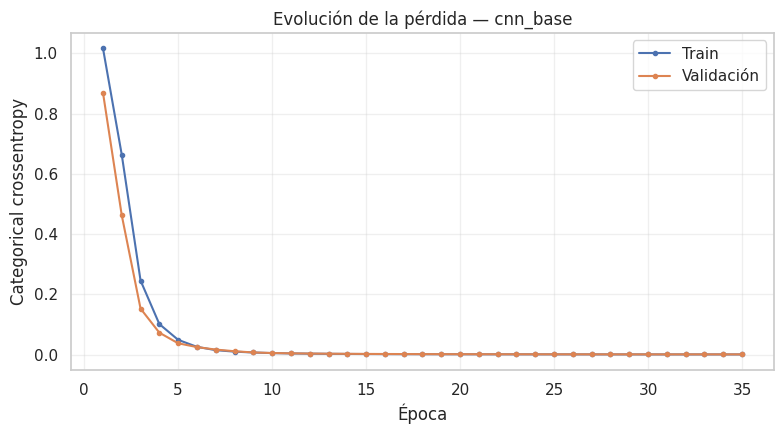

Gráfico guardado: /content/asl-cnn-aes/images/loss_cnn_base.png


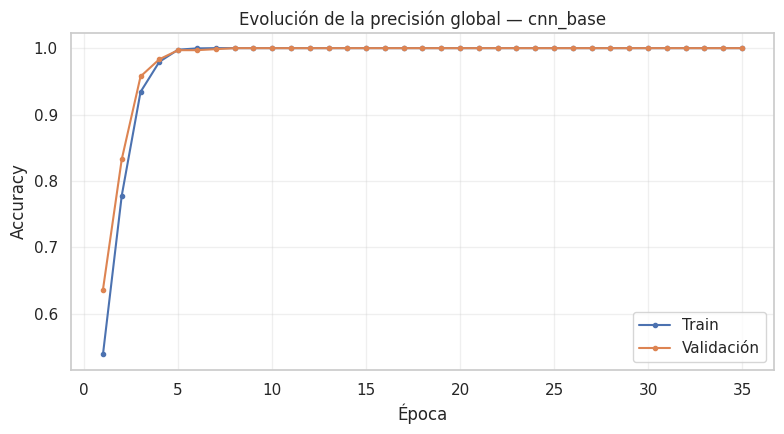

Gráfico guardado: /content/asl-cnn-aes/images/accuracy_cnn_base.png


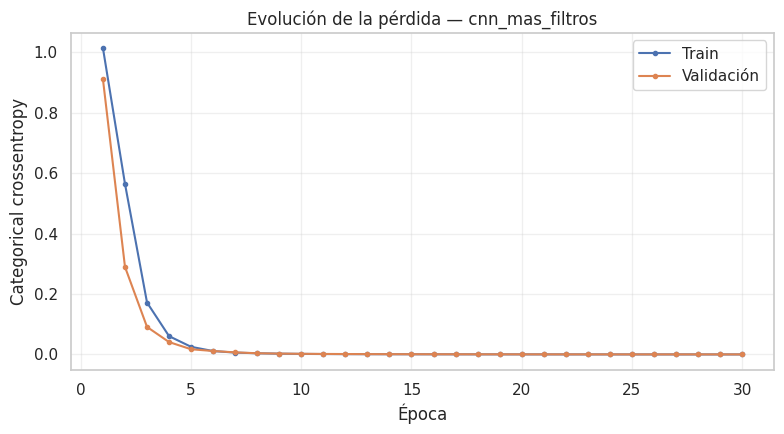

Gráfico guardado: /content/asl-cnn-aes/images/loss_cnn_mas_filtros.png


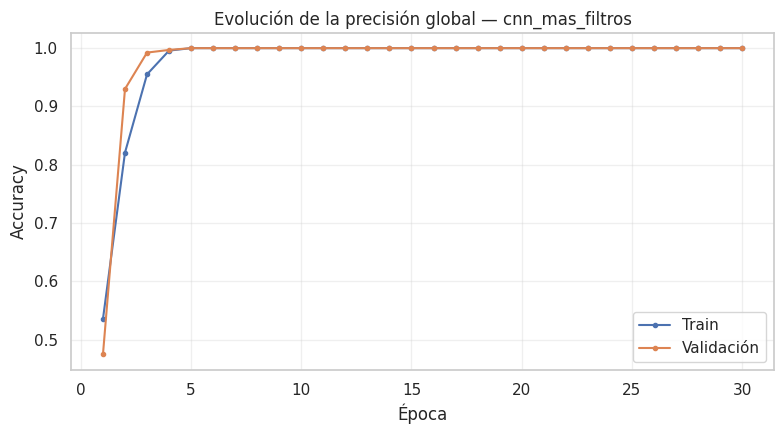

Gráfico guardado: /content/asl-cnn-aes/images/accuracy_cnn_mas_filtros.png


In [ ]:
for nombre, historial in historiales_cnn.items():
    epocas = np.arange(1, len(historial) + 1)

    for metrica, titulo, archivo, etiqueta_y in [
        ("loss", "Evolución de la pérdida", "loss", "Categorical crossentropy"),
        ("accuracy", "Evolución de la precisión global", "accuracy", "Accuracy"),
    ]:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.plot(epocas, historial[metrica], marker=".", label="Train")
        ax.plot(epocas, historial[f"val_{metrica}"], marker=".", label="Validación")
        ax.set(xlabel="Época", ylabel=etiqueta_y, title=f"{titulo} — {nombre}")
        ax.legend()
        ax.grid(alpha=0.3)
        fig.tight_layout()
        ruta_grafico = DIR_GRAFICOS_CNN / f"{archivo}_{nombre}.png"
        fig.savefig(ruta_grafico, dpi=130)
        plt.show()
        print("Gráfico guardado:", ruta_grafico)


## 14. Comparación de los modelos mediante validación

La selección se realiza por **menor `val_loss` del modelo con pesos restaurados**, sin usar el conjunto de prueba. `val_accuracy`, cantidad de parámetros, tiempos y épocas sirven de evidencia complementaria.

Se elige por pérdida de validación porque la función objetivo penaliza errores de clasificación con alta confianza, aunque la accuracy sea similar. Si la validación resulta sospechosamente perfecta, eso **no prueba** que los modelos generalicen mejor que la MLP original.

Las diferencias de tiempo solo se comparan como mediciones **dentro de esta ejecución**, ya que se hicieron en el mismo dispositivo. La MLP anterior debe reentrenarse bajo las mismas condiciones para una comparación de tiempo rigurosa.

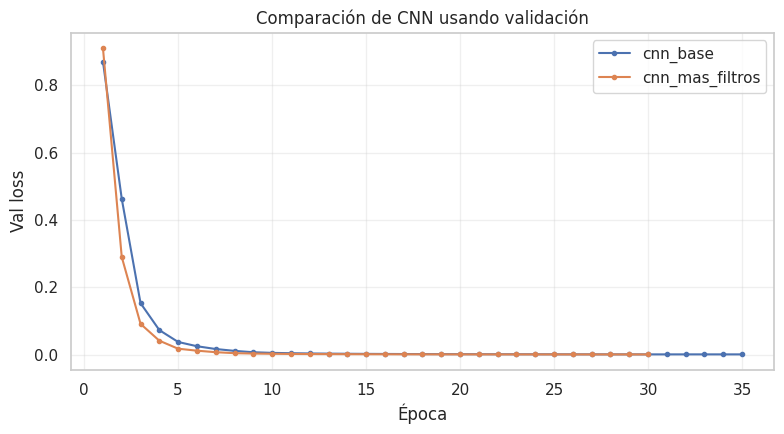

CNN seleccionada por val_loss: cnn_mas_filtros
Modelo guardado: /content/asl-cnn-aes/models/cnn_mas_filtros.keras


,modelo,parametros,epocas_ejecutadas,tiempo_fit_seg,train_accuracy_restaurado,val_accuracy_restaurado,val_loss_restaurado,gap_train_val_accuracy
0,cnn_mas_filtros,219779,30,129.38,1.0,1.0,0.0004,0.0
1,cnn_base,105411,35,87.44,1.0,1.0,0.0005,0.0


Resumen reproducible guardado: /content/asl-cnn-aes/reports/resultados_etapa3_cnn.json


In [ ]:
# Gráfico de validación de ambas CNN durante el entrenamiento.
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, historial in historiales_cnn.items():
    ax.plot(
        np.arange(1, len(historial) + 1),
        historial["val_loss"],
        marker=".", label=nombre,
    )
ax.set(xlabel="Época", ylabel="Val loss", title="Comparación de CNN usando validación")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DIR_GRAFICOS_CNN / "comparacion_val_loss_cnn.png", dpi=130)
plt.show()

tabla_ordenada = tabla_entrenamiento_cnn.sort_values(
    ["val_loss_restaurado", "parametros", "modelo"]
).reset_index(drop=True)
nombre_cnn_seleccionada = str(tabla_ordenada.loc[0, "modelo"])
modelo_cnn_seleccionado = modelos_cnn[nombre_cnn_seleccionada]
print("CNN seleccionada por val_loss:", nombre_cnn_seleccionada)
print("Modelo guardado:", DIR_MODELOS_CNN / f"{nombre_cnn_seleccionada}.keras")
display(
    tabla_ordenada[[
        "modelo", "parametros", "epocas_ejecutadas",
        "tiempo_fit_seg", "train_accuracy_restaurado",
        "val_accuracy_restaurado", "val_loss_restaurado",
        "gap_train_val_accuracy",
    ]].round(4)
)

resultado_experimento = {
    "generado_utc": datetime.now(timezone.utc).isoformat(),
    "semilla": SEED,
    "tensorflow": tf.__version__,
    "python": platform.python_version(),
    "dispositivos_gpu": [d.name for d in tf.config.list_physical_devices("GPU")],
    "modelo_seleccionado_por_val_loss": nombre_cnn_seleccionada,
    "configuraciones_filtros": CONFIGURACIONES_CNN,
    "hiperparametros": HIPERPARAMETROS,
    "tamanos": {"train": len(X_train), "val": len(X_val)},
    "resumenes": resumenes_cnn,
    "observaciones": [
        "Validación aleatoria estratificada; podrían existir variantes de una misma imagen de origen.",
        "Test original reservado: todavía no evaluado ni utilizado para elegir arquitectura.",
        "Tiempos no comparables con la MLP histórica sin reentrenarla en el mismo entorno.",
    ],
}
ruta_json = DIR_REPORTES_CNN / "resultados_etapa3_cnn.json"
with open(ruta_json, "w", encoding="utf-8") as archivo:
    json.dump(resultado_experimento, archivo, ensure_ascii=False, indent=2)
print("Resumen reproducible guardado:", ruta_json)


## 15. Interpretación y transición a la evaluación final

**Después de ejecutar las celdas anteriores, redacta conclusiones con estos valores:**

1. ¿Qué modelo obtuvo menor **val_loss**? Cita su valor numérico y la mejor época.
2. ¿Cómo evolucionó la curva de **train_loss** frente a **val_loss**? ¿Hubo oscilaciones o señales de sobreajuste?
3. ¿Se activó **EarlyStopping**? Indica cuántas épocas se ejecutaron y si se restauraron los pesos.
4. ¿Aumentar filtros mejoró la validación lo suficiente como para justificar el mayor número de parámetros y tiempo?
5. ¿La accuracy de validación parece sospechosamente alta dadas las variantes del dataset? Aclara que esta limitación impide asumir generalización a manos, personas o condiciones reales.

**Evidencias que deben existir tras ejecutar la etapa 3:**
- `models/cnn_base.keras` y `models/cnn_mas_filtros.keras`.
- `reports/historial_cnn_base.csv`, `reports/historial_cnn_mas_filtros.csv`, `reports/resumen_entrenamiento_cnn.csv` y `reports/resultados_etapa3_cnn.json`.
- `images/loss_cnn_base.png`, `images/accuracy_cnn_base.png`, sus equivalentes para la alternativa y `images/comparacion_val_loss_cnn.png`.

**Etapa 4 (pendiente):** evaluar **una vez** el modelo seleccionado sobre `X_test`; obtener accuracy, precision, recall, F1, matriz de confusión y errores por clase. Los Feature Maps y la comparación rigurosa con la MLP se desarrollarán después.

**No incluyas cifras inventadas en la defensa:** los resultados y gráficos se completan únicamente después de ejecutar realmente `fit()`.

In [ ]:
# Informe descriptivo basado en resultados reales de la ejecución.
for nombre, historia in historiales_cnn.items():
    fila = tabla_entrenamiento_cnn.set_index("modelo").loc[nombre]
    mejor_loss = float(historia["val_loss"].min())
    ultima_loss = float(historia["val_loss"].iloc[-1])
    max_accuracy = float(historia["val_accuracy"].max())
    print(f"\n--- {nombre} ---")
    print(
        f"val_loss inicial={historia['val_loss'].iloc[0]:.4f}; "
        f"mínimo={mejor_loss:.4f}; final={ultima_loss:.4f}"
    )
    print(
        f"val_accuracy máxima={max_accuracy:.2%}; "
        f"restaurada={fila['val_accuracy_restaurado']:.2%}"
    )
    print(
        "EarlyStopping antes de 40 épocas:",
        bool(fila["early_stopping_antes_max"])
    )
    print(
        "Brecha accuracy de train y validación (pesos restaurados):",
        f"{fila['gap_train_val_accuracy']:+.2%}"
    )
    if max_accuracy >= 0.995:
        print("ALERTA: validación casi perfecta; no prueba generalización externa.")
    if ultima_loss > mejor_loss * 1.20:
        print("La val_loss final supera al mínimo en más de 20 %; revisar curvas.")
print("Estas observaciones son un punto de partida, no conclusiones definitivas.")



--- cnn_base ---
val_loss inicial=0.8702; mínimo=0.0004; final=0.0004
val_accuracy máxima=100.00%; restaurada=100.00%
EarlyStopping antes de 40 épocas: True
Brecha accuracy de train y validación (pesos restaurados): +0.00%
ALERTA: validación casi perfecta; no prueba generalización externa.

--- cnn_mas_filtros ---
val_loss inicial=0.9101; mínimo=0.0003; final=0.0003
val_accuracy máxima=100.00%; restaurada=100.00%
EarlyStopping antes de 40 épocas: True
Brecha accuracy de train y validación (pesos restaurados): +0.00%
ALERTA: validación casi perfecta; no prueba generalización externa.
Estas observaciones son un punto de partida, no conclusiones definitivas.


---
## 16. Etapa 4 — Evaluación del modelo seleccionado con test oficial

**Objetivo:** medir por primera vez la generalización del modelo seleccionado en la etapa 3 sobre las **1.075 imágenes A, E y S** del archivo original `sign_mnist_test.csv`. Se incluyen accuracy, precision, recall, F1 macro, matriz de confusión y ejemplos de predicciones.

**Protocolo sin fuga de información:** en la etapa 3 se eligió la arquitectura exclusivamente por la menor pérdida de *validación* de los pesos restaurados, sin consultar `test`. En esta etapa se lee la selección fijada en `reports/resultados_etapa3_cnn.json`, se carga el archivo `.keras` ya entrenado y **no** se vuelve a ejecutar `fit()`, ajustar hiperparámetros ni cambiar de modelo según las métricas de test.

**Ejecución:** las celdas 16–20 pueden ejecutarse por separado sin repetir todo el entrenamiento, siempre que el repositorio (incluidos los modelos `.keras`, los CSV y el JSON de la etapa 3) esté disponible en `/content/asl-cnn-aes` o en la carpeta de trabajo. Para una sesión nueva de Colab, clona antes la rama `develop` y ejecuta únicamente las celdas de esta etapa. Si todavía existe una copia local del repositorio, no vuelvas a clonarlo sobre la misma ruta.

**Advertencia:** una puntuación del 100 % en validación no significa que la prueba real también lo sea; además, el dataset puede contener imágenes aumentadas relacionadas con fotos de origen. El test da evidencia sobre este conjunto, no sobre uso real con nuevos firmantes.

In [39]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, log_loss,
)

# Esta etapa se puede ejecutar en un kernel nuevo, SIN reentrenar.
CANDIDATAS_RAIZ = [
    Path("/content/asl-cnn-aes"),
    Path.cwd(),
    Path.cwd().parent,
]
RAIZ_ETAPA4 = next((
    p for p in CANDIDATAS_RAIZ
    if (p / "data" / "sign_mnist_test.csv").is_file()
    and (p / "reports" / "resultados_etapa3_cnn.json").is_file()
), None)
if RAIZ_ETAPA4 is None:
    raise FileNotFoundError(
        "No se encontró el repositorio con data/sign_mnist_test.csv y "
        "reports/resultados_etapa3_cnn.json. Clona la rama develop antes de ejecutar."
    )
RAIZ_ETAPA4 = RAIZ_ETAPA4.resolve()

with open(
    RAIZ_ETAPA4 / "reports" / "resultados_etapa3_cnn.json",
    encoding="utf-8",
) as archivo:
    seleccion_etapa3 = json.load(archivo)

nombre_modelo_test = seleccion_etapa3["modelo_seleccionado_por_val_loss"]
if nombre_modelo_test not in {"cnn_base", "cnn_mas_filtros"}:
    raise ValueError("El JSON de entrenamiento contiene un modelo desconocido.")
ruta_modelo_test = RAIZ_ETAPA4 / "models" / f"{nombre_modelo_test}.keras"
if not ruta_modelo_test.is_file():
    raise FileNotFoundError(f"Modelo entrenado ausente: {ruta_modelo_test}")

# Se cargan los pesos ya entrenados, sin compilar ni realizar fit().
modelo_test = keras.models.load_model(ruta_modelo_test, compile=False)
if modelo_test.input_shape[1:] != (28, 28, 1) or modelo_test.output_shape[-1] != 3:
    raise ValueError("La arquitectura del modelo no coincide con los datos A/E/S.")

# Usar solo el conjunto oficial de test original, nunca train/val.
df_test_oficial = pd.read_csv(RAIZ_ETAPA4 / "data" / "sign_mnist_test.csv")
mapa_original_a_nuevo = {0: 0, 4: 1, 18: 2}
columnas_imagen_test = [f"pixel{i}" for i in range(1, 785)]
df_test_aes = df_test_oficial.loc[
    df_test_oficial["label"].isin(mapa_original_a_nuevo)
].copy()
X_test_e4 = (
    df_test_aes[columnas_imagen_test].to_numpy(dtype=np.float32)
    .reshape(-1, 28, 28, 1) / 255.0
)
y_test_e4 = (
    df_test_aes["label"].map(mapa_original_a_nuevo).to_numpy(dtype=np.int64)
)
NOMBRES_E4 = ["A", "E", "S"]
assert X_test_e4.shape == (1075, 28, 28, 1)
assert len(y_test_e4) == 1075 and set(np.unique(y_test_e4)) == {0, 1, 2}
assert np.isfinite(X_test_e4).all() and 0.0 <= X_test_e4.min() <= X_test_e4.max() <= 1.0

print("Modelo fijado en etapa 3:", nombre_modelo_test)
print("Parámetros:", f"{modelo_test.count_params():,}")
print("Entrada test oficial:", X_test_e4.shape)
print("Keras:", keras.__version__, "| Backend:", keras.backend.backend())


Modelo fijado en etapa 3: cnn_mas_filtros
Parámetros: 219,779
Entrada test oficial: (1075, 28, 28, 1)
Keras: 3.13.2 | Backend: tensorflow


In [40]:
# Evaluación: se predice SOLO con el modelo previamente seleccionado.
probabilidades_test_e4 = modelo_test.predict(X_test_e4, batch_size=64, verbose=0)
assert probabilidades_test_e4.shape == (1075, 3)
assert np.isfinite(probabilidades_test_e4).all()
assert np.allclose(probabilidades_test_e4.sum(axis=1), 1.0, atol=1e-4)

predicciones_test_e4 = probabilidades_test_e4.argmax(axis=1)
reporte_test_e4 = classification_report(
    y_test_e4, predicciones_test_e4,
    labels=[0, 1, 2], target_names=NOMBRES_E4,
    zero_division=0, output_dict=True,
)
matriz_test_e4 = confusion_matrix(
    y_test_e4, predicciones_test_e4, labels=[0, 1, 2]
)
metricas_test_e4 = {
    "accuracy": float(accuracy_score(y_test_e4, predicciones_test_e4)),
    "precision_macro": float(precision_score(
        y_test_e4, predicciones_test_e4, average="macro", zero_division=0
    )),
    "recall_macro": float(recall_score(
        y_test_e4, predicciones_test_e4, average="macro", zero_division=0
    )),
    "f1_macro": float(f1_score(
        y_test_e4, predicciones_test_e4, average="macro", zero_division=0
    )),
    "log_loss": float(log_loss(
        y_test_e4, probabilidades_test_e4, labels=[0, 1, 2]
    )),
}

print("\n=== Métricas sobre test oficial ===")
print(pd.Series(metricas_test_e4).round(6).to_string())
print("\n=== Reporte por clase ===")
print(classification_report(
    y_test_e4, predicciones_test_e4,
    labels=[0, 1, 2], target_names=NOMBRES_E4,
    zero_division=0,
))
print("Correctas:", int((y_test_e4 == predicciones_test_e4).sum()))
print("Incorrectas:", int((y_test_e4 != predicciones_test_e4).sum()))



=== Métricas sobre test oficial ===
accuracy           0.979535
precision_macro    0.985012
recall_macro       0.970875
f1_macro           0.977245
log_loss           0.041318

=== Reporte por clase ===
              precision    recall  f1-score   support

           A       1.00      1.00      1.00       331
           E       0.96      1.00      0.98       498
           S       1.00      0.91      0.95       246

    accuracy                           0.98      1075
   macro avg       0.99      0.97      0.98      1075
weighted avg       0.98      0.98      0.98      1075

Correctas: 1053
Incorrectas: 22


## 17. Matriz de confusión e interpretación por clase

Filas = letra real; columnas = letra predicha. La diagonal contiene aciertos, y los valores fuera de ella indican confusiones. Mostraremos también la matriz **normalizada por fila** para visualizar el porcentaje detectado dentro de cada letra.

Si, por ejemplo, S se confunde mayoritariamente con E, ese hallazgo tiene implicaciones para reconocer formas de mano parecidas; debe discutirse con números reales, no con hipótesis generales.

,precision,recall,f1-score,support
A,1.0000,1.0000,1.0000,331.0
E,0.9595,0.9980,0.9783,498.0
S,0.9956,0.9146,0.9534,246.0


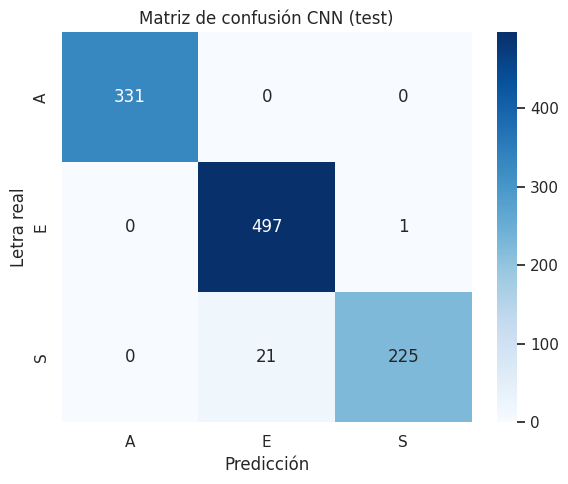

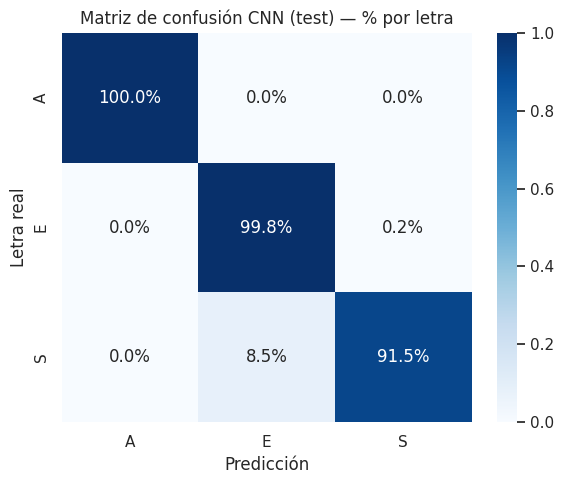

Confusiones observadas (real → predicho):
 E → S: 1 imágenes
 S → E: 21 imágenes


In [41]:
DIR_REPORTES_E4 = RAIZ_ETAPA4 / "reports"
DIR_IMAGENES_E4 = RAIZ_ETAPA4 / "images"
DIR_REPORTES_E4.mkdir(exist_ok=True, parents=True)
DIR_IMAGENES_E4.mkdir(exist_ok=True, parents=True)

tabla_clases_test_e4 = pd.DataFrame(reporte_test_e4).T.loc[
    NOMBRES_E4, ["precision", "recall", "f1-score", "support"]
]
display(tabla_clases_test_e4.round(4))
pd.DataFrame(
    matriz_test_e4, index=NOMBRES_E4, columns=NOMBRES_E4
).to_csv(DIR_REPORTES_E4 / "matriz_confusion_test_cnn.csv")
tabla_clases_test_e4.to_csv(DIR_REPORTES_E4 / "metricas_por_clase_test_cnn.csv")

for normalizar in [False, True]:
    valores = (
        matriz_test_e4 / np.maximum(matriz_test_e4.sum(axis=1, keepdims=True), 1)
        if normalizar else matriz_test_e4
    )
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        valores, annot=True, fmt=".1%" if normalizar else "d",
        cmap="Blues", xticklabels=NOMBRES_E4, yticklabels=NOMBRES_E4,
        cbar=True, ax=ax,
    )
    ax.set(
        xlabel="Predicción",
        ylabel="Letra real",
        title="Matriz de confusión CNN (test)" +
              (" — % por letra" if normalizar else ""),
    )
    fig.tight_layout()
    archivo = (
        "matriz_confusion_test_cnn_normalizada.png"
        if normalizar else "matriz_confusion_test_cnn.png"
    )
    fig.savefig(DIR_IMAGENES_E4 / archivo, dpi=140)
    plt.show()

print("Confusiones observadas (real → predicho):")
for real in range(3):
    for pred in range(3):
        if real != pred and matriz_test_e4[real, pred] > 0:
            print(
                f" {NOMBRES_E4[real]} → {NOMBRES_E4[pred]}: "
                f"{matriz_test_e4[real, pred]} imágenes"
            )


## 18. Ejemplos de aciertos y errores

Mostraremos una muestra reproducible de predicciones correctas y los errores en los que el modelo se equivocó con más confianza. El objetivo no es solamente exponer imágenes, sino **explicar cuáles formas de mano se confunden y cómo la resolución 28×28 podría influir**.

Elegir los errores más seguros muestra fallos relevantes, pero no representa una muestra aleatoria de todos los errores. Todas las imágenes proceden del test **después de** fijar la arquitectura; estos ejemplos sirven para análisis descriptivo, nunca para volver a seleccionar hiperparámetros.

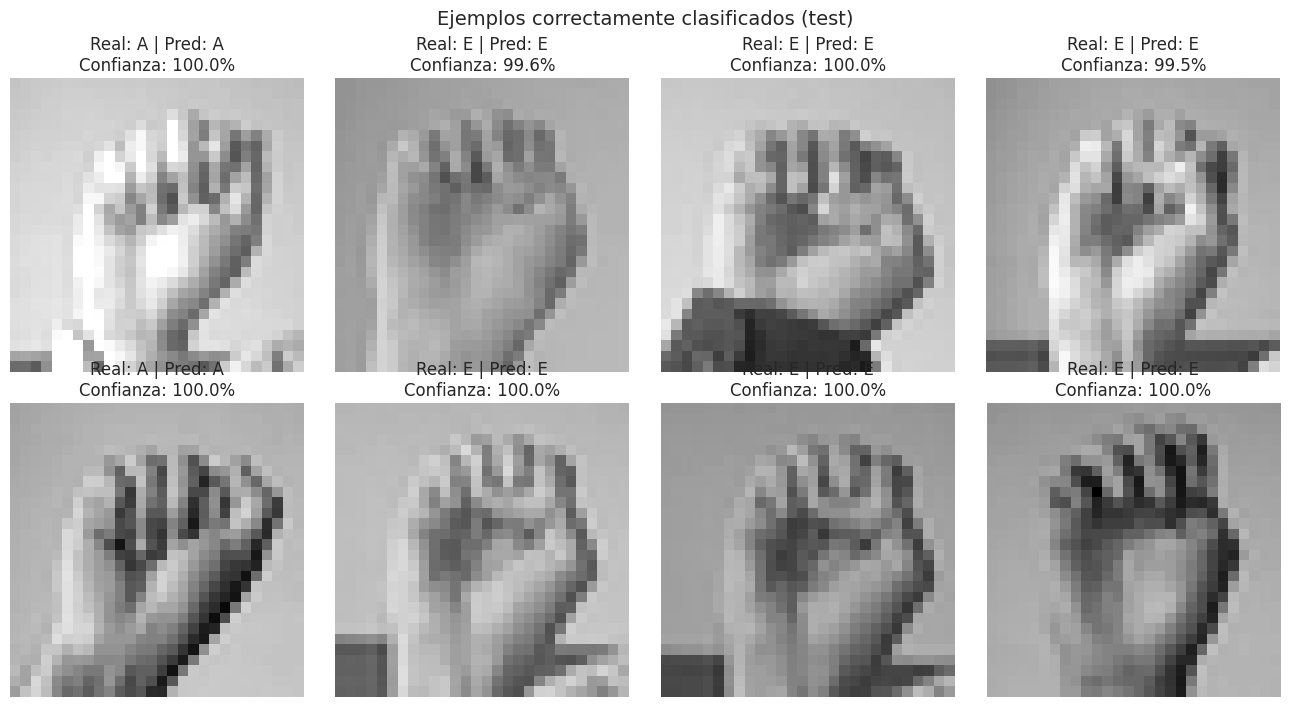

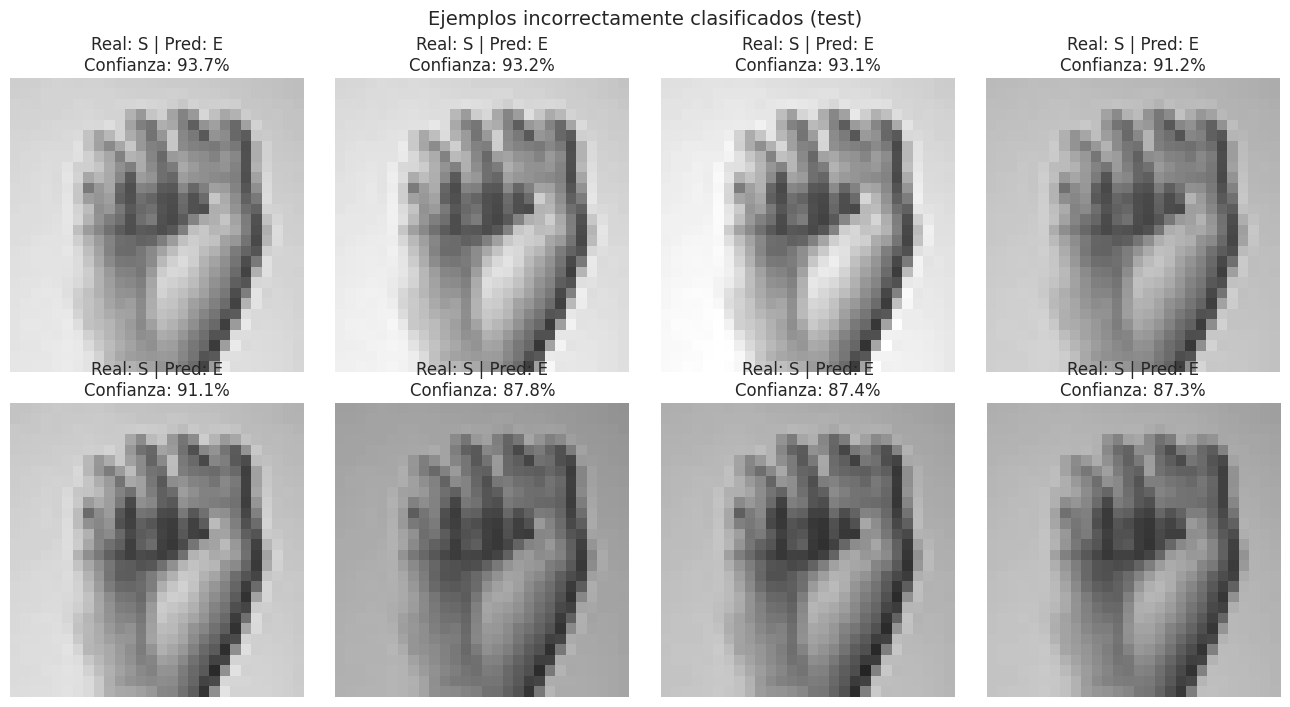

In [42]:
indices_correctos_e4 = np.flatnonzero(predicciones_test_e4 == y_test_e4)
indices_errores_e4 = np.flatnonzero(predicciones_test_e4 != y_test_e4)
rng_e4 = np.random.default_rng(42)
ejemplos_ok_e4 = rng_e4.choice(
    indices_correctos_e4, size=min(8, len(indices_correctos_e4)),
    replace=False,
)
ejemplos_error_e4 = sorted(
    indices_errores_e4,
    key=lambda idx: float(probabilidades_test_e4[idx, predicciones_test_e4[idx]]),
    reverse=True,
)[:8]

def mostrar_ejemplos_e4(indices, titulo, nombre_archivo):
    if len(indices) == 0:
        print(f"{titulo}: no hay imágenes para mostrar.")
        return
    columnas = min(4, len(indices))
    filas = int(np.ceil(len(indices) / columnas))
    fig, axes = plt.subplots(
        filas, columnas, figsize=(3.3 * columnas, 3.6 * filas),
        squeeze=False,
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, indice in zip(axes.flat, indices):
        ax.imshow(X_test_e4[indice].squeeze(), cmap="gray", vmin=0, vmax=1)
        real = NOMBRES_E4[y_test_e4[indice]]
        pred = NOMBRES_E4[predicciones_test_e4[indice]]
        confianza = probabilidades_test_e4[indice, predicciones_test_e4[indice]]
        ax.set_title(f"Real: {real} | Pred: {pred}\nConfianza: {confianza:.1%}")
    fig.suptitle(titulo, fontsize=14)
    fig.tight_layout()
    fig.savefig(DIR_IMAGENES_E4 / nombre_archivo, dpi=140)
    plt.show()

mostrar_ejemplos_e4(
    ejemplos_ok_e4, "Ejemplos correctamente clasificados (test)",
    "ejemplos_correctos_test_cnn.png",
)
mostrar_ejemplos_e4(
    ejemplos_error_e4, "Ejemplos incorrectamente clasificados (test)",
    "ejemplos_errores_test_cnn.png",
)


## 19. Comparación descriptiva con la MLP de la EP1

Resultados históricos documentados de la MLP: **1.016/1.075 aciertos**, accuracy ≈ **94,51 %** y F1 macro ≈ **93,65 %**. Al haberse utilizado el mismo test original A/E/S, podemos comparar resultados descriptivamente; sin embargo, la validación del dataset sigue siendo susceptible a imágenes relacionadas, y **no podemos comparar tiempos de entrenamiento** sin reentrenar ambas arquitecturas en condiciones equivalentes.

Esta comparación **no utiliza resultados de MLP para elegir la CNN**, que ya quedó seleccionada durante la etapa 3. En la etapa 5 volveremos a evaluar la MLP bajo un protocolo común y veremos los mapas de características de la CNN.

**Aspectos éticos:** el clasificador solo distingue tres signos estáticos de ASL; no es un traductor de frases, ni reconoce LSCh, ni está validado con personas nuevas.

In [43]:
# Exportación: resultados medidos, sin inventar cifras.
resumen_e4 = {
    "dataset": "Sign Language MNIST — test original (A,E,S)",
    "modelo_elegido_previamente": nombre_modelo_test,
    "regla_de_seleccion_previa": "menor val_loss restaurada (etapa 3)",
    "sin_reentrenar_en_test": True,
    "n_test": int(len(y_test_e4)),
    "aciertos": int((y_test_e4 == predicciones_test_e4).sum()),
    "errores": int((y_test_e4 != predicciones_test_e4).sum()),
    "backend": keras.backend.backend(),
    "keras_version": keras.__version__,
    "metricas": metricas_test_e4,
    "matriz_confusion": matriz_test_e4.tolist(),
    "clases": NOMBRES_E4,
    "reporte_clasificacion": reporte_test_e4,
    "mlp_ep1_referencia": {
        "aciertos": 1016, "n_test": 1075, "f1_macro_reportado": 0.9365,
    },
    "limitaciones": [
        "Los resultados corresponden solo al dataset académico con tres letras ASL.",
        "El dataset puede contener variantes de fotos de origen; validar con nuevos sujetos en el futuro.",
        "No se comparan los tiempos con la MLP histórica por carecer de igualdad de condiciones.",
        "No cambiar arquitectura o hiperparámetros basándose en este test.",
    ],
}
with open(
    DIR_REPORTES_E4 / "metricas_test_cnn.json", "w", encoding="utf-8"
) as archivo:
    json.dump(resumen_e4, archivo, indent=2, ensure_ascii=False)

pd.DataFrame([
    {"metrica": k, "valor": v}
    for k, v in metricas_test_e4.items()
]).to_csv(DIR_REPORTES_E4 / "metricas_test_cnn.csv", index=False)

accuracy_mlp_ep1 = 1016 / 1075
diferencia_pp_e4 = (metricas_test_e4["accuracy"] - accuracy_mlp_ep1) * 100
print(
    f"CNN test: {metricas_test_e4['accuracy']:.2%} | "
    f"MLP EP1 test: {accuracy_mlp_ep1:.2%} | "
    f"Diferencia: {diferencia_pp_e4:+.2f} puntos porcentuales"
)
print("Reportes guardados:", DIR_REPORTES_E4)
print("Imágenes guardadas:", DIR_IMAGENES_E4)


CNN test: 97.95% | MLP EP1 test: 94.51% | Diferencia: +3.44 puntos porcentuales
Reportes guardados: /content/asl-cnn-aes/reports
Imágenes guardadas: /content/asl-cnn-aes/images


## 20. Conclusiones de la etapa 4 y siguiente paso

Tras ejecutar las celdas de la etapa 4, responde utilizando las cifras que aparezcan en el notebook:

1. ¿Superó la CNN los objetivos de accuracy mayor a 90 %, F1 macro mayor a 0,85 y recall por clase mayor a 0,80?
2. ¿Qué letra tuvo menor recall y qué confusión domina la matriz?
3. ¿La CNN mejoró frente a la MLP de EP1? Reporta la diferencia de accuracy en **puntos porcentuales**, no solamente el porcentaje relativo.
4. ¿Qué enseñan los ejemplos mal clasificados sobre las diferencias sutiles entre señas?
5. ¿Qué limita la generalización a fotografías de manos de personas nuevas?

**Archivos resultantes:** `reports/metricas_test_cnn.json`, `reports/metricas_test_cnn.csv`, `reports/metricas_por_clase_test_cnn.csv`, `reports/matriz_confusion_test_cnn.csv` y cuatro PNG en `images/`. Los datos reales y pesos se guardan de forma separada; subir los artefactos generados a GitHub es otro paso.

**Siguiente etapa (5):** comparación detallada con la MLP, visualización de Feature Maps y mapas de activación por clase, limitaciones y conclusiones para la defensa. La etapa 5 no debe retocar el modelo utilizando el test.

---
## 21. Etapa 5 — Comparación MLP frente a CNN e interpretación interna

**Objetivos:** (1) comparar de manera reproducible el modelo MLP original con la CNN seleccionada; (2) visualizar los *Feature Maps* de ambas convoluciones; (3) crear **mapas de activación por clase** mediante Grad-CAM; (4) preparar conclusiones y la defensa técnica.

**Criterio metodológico:** la CNN quedó seleccionada en la etapa 3 usando solo validación. Esta sección **no ajusta ni vuelve a seleccionar** la CNN a partir del conjunto de test. La MLP original se carga como referencia y se evalúa sobre las **mismas 1.075 imágenes test**, con el mismo orden de clases y normalización.

Si acabas de abrir una sesión nueva de Colab, clona la rama `develop` y **ejecuta primero las celdas de la etapa 4** (secciones 16–20). Así quedarán definidos `RAIZ_ETAPA4`, `X_test_e4`, `y_test_e4`, `modelo_test`, `predicciones_test_e4` y `metricas_test_e4`. No ejecutes nuevamente las celdas de entrenamiento de la etapa 3.

Los tiempos históricos de la CNN no se comparan directamente con la MLP si no han sido medidos bajo las mismas condiciones. Más adelante se incluye un *benchmark opcional* de las tres arquitecturas en un mismo entorno.

In [46]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not all(k in globals() for k in (
    "RAIZ_ETAPA4", "X_test_e4", "y_test_e4",
    "modelo_test", "predicciones_test_e4", "metricas_test_e4"
)):
    raise RuntimeError(
        "Primero ejecuta las celdas de la etapa 4 (secciones 16–20). "
        "No necesitas reentrenar los modelos."
    )

ruta_mlp_e5 = RAIZ_ETAPA4 / "models" / "mlp_asl_aes.keras"
if not ruta_mlp_e5.is_file():
    raise FileNotFoundError(f"No se encontró la MLP original en {ruta_mlp_e5}")

mlp_e5 = keras.Sequential([
    keras.Input(shape=(784,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])


mlp_e5.load_weights(str(ruta_mlp_e5), skip_mismatch=False)

assert mlp_e5.input_shape[-1] == 784 and mlp_e5.output_shape[-1] == 3


# MLP: vectores de 784 píxeles; CNN: imágenes (28,28,1).
X_mlp_test_e5 = X_test_e4.reshape(-1, 784)
prob_mlp_e5 = mlp_e5.predict(X_mlp_test_e5, batch_size=64, verbose=0)
assert prob_mlp_e5.shape == (1075, 3)
assert np.allclose(prob_mlp_e5.sum(axis=1), 1, atol=1e-4)
pred_mlp_e5 = prob_mlp_e5.argmax(axis=1)

def metricas_multiclase_e5(etiquetas, predicciones):
    return {
        "accuracy": float(accuracy_score(etiquetas, predicciones)),
        "precision_macro": float(precision_score(
            etiquetas, predicciones, average="macro", zero_division=0
        )),
        "recall_macro": float(recall_score(
            etiquetas, predicciones, average="macro", zero_division=0
        )),
        "f1_macro": float(f1_score(
            etiquetas, predicciones, average="macro", zero_division=0
        )),
    }

metricas_mlp_e5 = metricas_multiclase_e5(y_test_e4, pred_mlp_e5)
metricas_cnn_e5 = metricas_multiclase_e5(y_test_e4, predicciones_test_e4)
tabla_comparativa_e5 = pd.DataFrame({
    "MLP original (checkpoint)": metricas_mlp_e5,
    "CNN seleccionada (checkpoint)": metricas_cnn_e5,
}).T
tabla_comparativa_e5["parametros"] = [
    mlp_e5.count_params(), modelo_test.count_params()
]
tabla_comparativa_e5["aciertos"] = [
    int(np.sum(pred_mlp_e5 == y_test_e4)),
    int(np.sum(predicciones_test_e4 == y_test_e4)),
]
display(tabla_comparativa_e5.round(5))
tabla_comparativa_e5.to_csv(
    DIR_REPORTES_E4 / "comparacion_mlp_cnn_test.csv", index_label="modelo"
)

print("\nMatriz de confusión MLP (A,E,S):")
print(confusion_matrix(y_test_e4, pred_mlp_e5, labels=[0, 1, 2]))
print("\nDiferencia de accuracy CNN - MLP (puntos porcentuales):")
print(f"{100 * (metricas_cnn_e5['accuracy'] - metricas_mlp_e5['accuracy']):+.2f} pp")
if abs(metricas_mlp_e5["accuracy"] - 1016/1075) > 1e-6:
    print("AVISO: el checkpoint MLP reproduce cifras distintas a las de la EP1.")
    print("Usa los números realmente observados en este experimento y explícalo.")


,accuracy,precision_macro,recall_macro,f1_macro,parametros,aciertos
MLP original (checkpoint),0.94512,0.93880,0.93514,0.93650,108931,1016
CNN seleccionada (checkpoint),0.97953,0.98501,0.97088,0.97725,219779,1053



Matriz de confusión MLP (A,E,S):
[[331   0   0]
 [  0 476  22]
 [ 16  21 209]]

Diferencia de accuracy CNN - MLP (puntos porcentuales):
+3.44 pp


## 22. Comparación por letra y patrones de errores

La accuracy global puede ocultar dificultades en letras específicas. Compararemos el **recall de A, E y S** usando exactamente el mismo test.

La CNN ya mostró un patrón de error dominante **S → E** (21 ejemplos). La hipótesis es que conservar relaciones espaciales mediante filtros puede mejorar la distinción de posiciones sutiles de los dedos, pero esta hipótesis se debe contrastar con las matrices y ejemplos; **no se atribuyen automáticamente capacidades semánticas a filtros individuales**.

,letra,recall_mlp,recall_cnn,f1_mlp,f1_cnn,mejora_recall_pp
0,A,1.0000,1.0000,0.9764,1.0000,0.0000
1,E,0.9558,0.9980,0.9568,0.9783,4.2169
2,S,0.8496,0.9146,0.8763,0.9534,6.5041


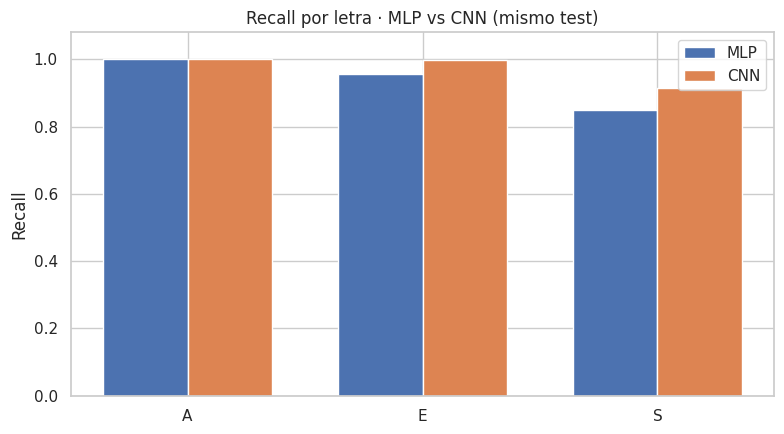

Ambos modelos fallan: 22
Solo la MLP falla: 37
Solo la CNN falla: 0
Las diferencias de aciertos son descriptivas en este test, no prueba de desempeño en sujetos nuevos.


In [47]:
nombres_e5 = ["A", "E", "S"]
reporte_mlp_e5 = classification_report(
    y_test_e4, pred_mlp_e5, labels=[0,1,2],
    target_names=nombres_e5, zero_division=0, output_dict=True,
)
reporte_cnn_e5 = classification_report(
    y_test_e4, predicciones_test_e4, labels=[0,1,2],
    target_names=nombres_e5, zero_division=0, output_dict=True,
)
tabla_por_letra_e5 = pd.DataFrame({
    "letra": nombres_e5,
    "recall_mlp": [reporte_mlp_e5[k]["recall"] for k in nombres_e5],
    "recall_cnn": [reporte_cnn_e5[k]["recall"] for k in nombres_e5],
    "f1_mlp": [reporte_mlp_e5[k]["f1-score"] for k in nombres_e5],
    "f1_cnn": [reporte_cnn_e5[k]["f1-score"] for k in nombres_e5],
})
tabla_por_letra_e5["mejora_recall_pp"] = (
    tabla_por_letra_e5["recall_cnn"] - tabla_por_letra_e5["recall_mlp"]
) * 100
display(tabla_por_letra_e5.round(4))
tabla_por_letra_e5.to_csv(
    DIR_REPORTES_E4 / "comparacion_por_letra_mlp_cnn.csv", index=False
)

pos_e5 = np.arange(3)
ancho_e5 = 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pos_e5-ancho_e5/2, tabla_por_letra_e5["recall_mlp"],
       ancho_e5, label="MLP")
ax.bar(pos_e5+ancho_e5/2, tabla_por_letra_e5["recall_cnn"],
       ancho_e5, label="CNN")
ax.set_xticks(pos_e5, nombres_e5)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Recall")
ax.set_title("Recall por letra · MLP vs CNN (mismo test)")
ax.legend()
fig.tight_layout()
fig.savefig(DIR_IMAGENES_E4 / "comparacion_recall_mlp_cnn.png", dpi=140)
plt.show()

errores_mlp_e5 = np.flatnonzero(pred_mlp_e5 != y_test_e4)
errores_cnn_e5 = np.flatnonzero(predicciones_test_e4 != y_test_e4)
ambas_e5 = np.intersect1d(errores_mlp_e5, errores_cnn_e5)
solo_mlp_e5 = np.setdiff1d(errores_mlp_e5, errores_cnn_e5)
solo_cnn_e5 = np.setdiff1d(errores_cnn_e5, errores_mlp_e5)
print("Ambos modelos fallan:", len(ambas_e5))
print("Solo la MLP falla:", len(solo_mlp_e5))
print("Solo la CNN falla:", len(solo_cnn_e5))
print(
    "Las diferencias de aciertos son descriptivas en este test, "
    "no prueba de desempeño en sujetos nuevos."
)


## 23. Feature Maps: ¿qué extraen las capas convolucionales?

Un **Feature Map** es la salida de un filtro al procesar una imagen. En el primer bloque es frecuente observar respuestas a rasgos visuales simples; bloques más profundos combinan información de regiones más amplias.

Para tres imágenes de prueba (una de cada clase, correctamente clasificadas), visualizaremos ocho canales de `conv_bordes` y ocho de `conv_patrones`. En nuestra arquitectura, los mapas tienen tamaño **28×28** y **14×14**, respectivamente. Mostrar canales seleccionados y reescalados **no demuestra** que un canal represente específicamente un dedo o una letra; solo indica dónde se activó el filtro.

Se elige el primer ejemplo correctamente clasificado de cada clase en orden original del test: selección **determinista para visualización**, sin optimización de pesos.

Índices de imágenes representativas: {'A': 0, 'E': 1, 'S': 5}
Forma primer bloque: (3, 28, 28, 32)
Forma segundo bloque: (3, 14, 14, 64)


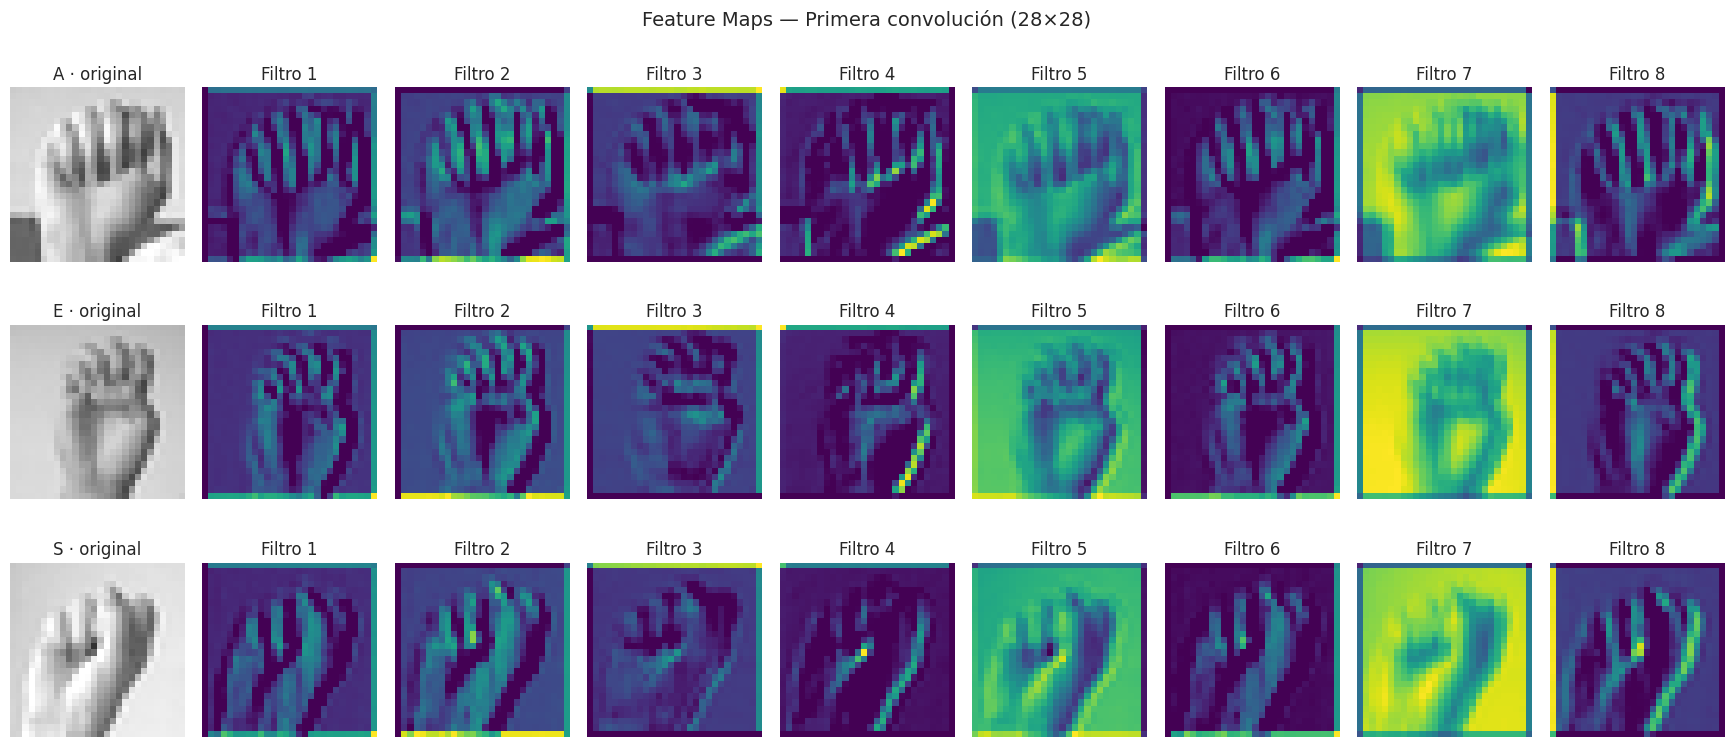

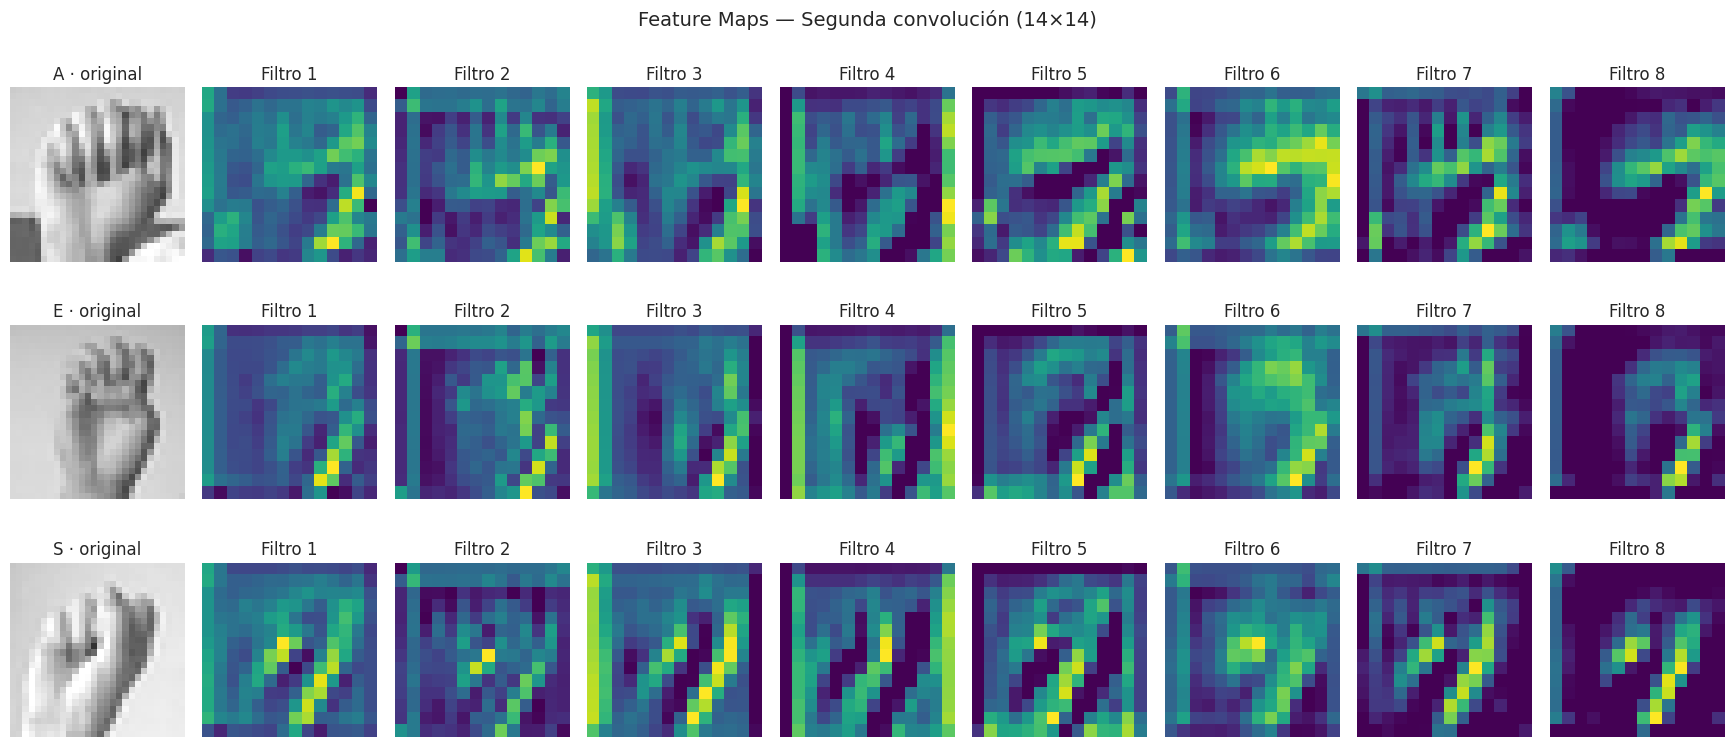

In [48]:
import keras

indices_representantes_e5 = {}
for clase_idx, letra in enumerate(nombres_e5):
    candidatos = np.flatnonzero(
        (y_test_e4 == clase_idx) & (predicciones_test_e4 == clase_idx)
    )
    if len(candidatos) == 0:
        raise ValueError(f"No existen aciertos de test para la letra {letra}.")
    indices_representantes_e5[letra] = int(candidatos[0])
print("Índices de imágenes representativas:", indices_representantes_e5)

modelo_featuremaps_e5 = keras.Model(
    inputs=modelo_test.inputs,
    outputs=[
        modelo_test.get_layer("conv_bordes").output,
        modelo_test.get_layer("conv_patrones").output,
    ],
)

imagenes_rep_e5 = X_test_e4[
    list(indices_representantes_e5.values())
].astype(np.float32)
mapas_primera_e5, mapas_segunda_e5 = modelo_featuremaps_e5.predict(
    imagenes_rep_e5, verbose=0
)
print("Forma primer bloque:", mapas_primera_e5.shape)
print("Forma segundo bloque:", mapas_segunda_e5.shape)

for titulo, mapas, ruta in [
    ("Primera convolución (28×28)", mapas_primera_e5,
     "feature_maps_primera_conv.png"),
    ("Segunda convolución (14×14)", mapas_segunda_e5,
     "feature_maps_segunda_conv.png"),
]:
    fig, axes = plt.subplots(3, 9, figsize=(17.5, 8))
    for fila, letra in enumerate(nombres_e5):
        axes[fila, 0].imshow(
            imagenes_rep_e5[fila].squeeze(), cmap="gray", vmin=0, vmax=1
        )
        axes[fila, 0].set_title(f"{letra} · original")
        axes[fila, 0].axis("off")
        for canal in range(8):
            respuesta = mapas[fila, :, :, canal]
            axes[fila, canal+1].imshow(respuesta, cmap="viridis")
            axes[fila, canal+1].set_title(f"Filtro {canal+1}")
            axes[fila, canal+1].axis("off")
    fig.suptitle(f"Feature Maps — {titulo}", fontsize=14)
    fig.tight_layout()
    fig.savefig(DIR_IMAGENES_E4 / ruta, dpi=140)
    plt.show()


## 24. Mapas de activación de cada clase mediante Grad-CAM

Para cumplir con la visualización de activación por clase, usamos **Grad-CAM** sobre la segunda convolución (`conv_patrones`). Calcula qué regiones influyen más **positivamente** en la puntuación de una clase dada.

Por cada imagen representativa A, E y S, generaremos tres mapas: **activación de la clase A, de la E y de la S**, junto con la foto original. Así se distinguen los mapas condicionados por clase de los *Feature Maps* de filtros individuales.

Para evitar gradientes extremadamente pequeños cuando softmax está saturado, se calcula el gradiente de la **puntuación anterior a softmax (logit)** usando exactamente los pesos de la última capa densa, sin alterar el modelo guardado. El resultado es una herramienta de interpretación aproximada, **no una segmentación ni una prueba causal** de qué dedo decide la clase.

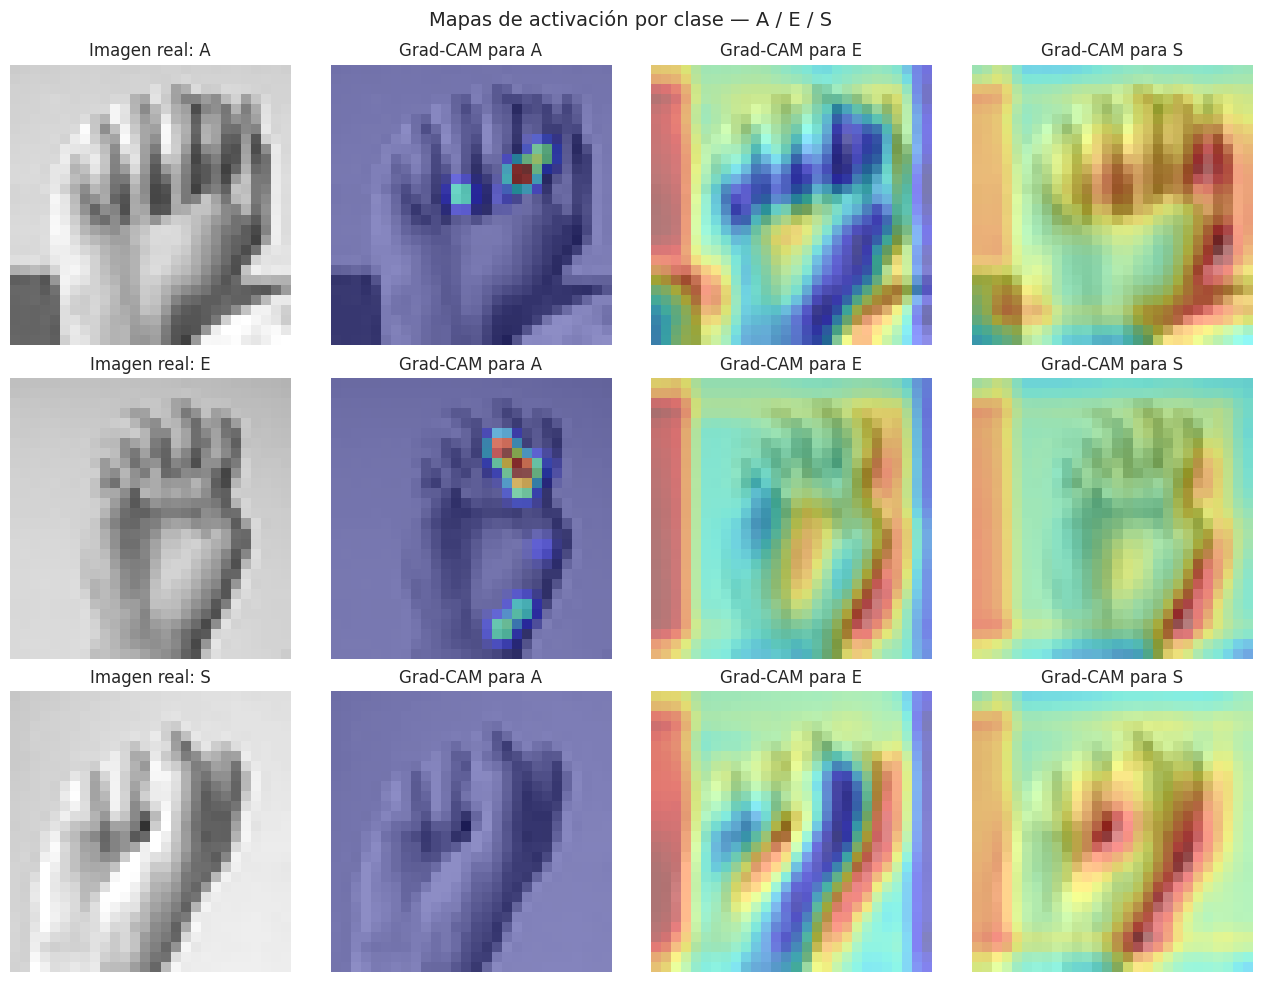

Aviso: mapas sin contribuciones positivas: [('S', 'A')] (no se deben interpretar como ausencia de información visual).


In [49]:
import tensorflow as tf

if keras.backend.backend() != "tensorflow":
    raise RuntimeError(
        "Grad-CAM de esta etapa requiere Keras con backend TensorFlow. "
        "Ejecuta esta celda en Google Colab."
    )

capa_salida_e5 = modelo_test.get_layer("salida_aes")
if capa_salida_e5.units != 3:
    raise ValueError("Se esperaba una salida Dense con 3 clases.")

def calcular_gradcam_e5(imagen, clase):
    """Grad-CAM del logit para una clase; no modifica los pesos del modelo."""
    tensor = tf.convert_to_tensor(imagen[None, ...], dtype=tf.float32)
    with tf.GradientTape() as cinta:
        x = tensor
        activacion_conv = None
        for capa in modelo_test.layers:
            if capa.name == "salida_aes":
                break
            # Esta CNN no tiene Dropout ni BatchNorm: las capas pueden
            # llamarse directamente sin modificar su comportamiento.
            x = capa(x)
            if capa.name == "conv_patrones":
                activacion_conv = x
        if activacion_conv is None:
            raise ValueError("No se encontró la capa conv_patrones.")
        logits = tf.linalg.matmul(x, capa_salida_e5.kernel)
        if capa_salida_e5.bias is not None:
            logits = logits + capa_salida_e5.bias
        puntuacion_clase = logits[:, clase]

    gradientes = cinta.gradient(puntuacion_clase, activacion_conv)
    if gradientes is None:
        raise RuntimeError("No se pudieron calcular los gradientes de Grad-CAM.")
    pesos_canales = tf.reduce_mean(gradientes, axis=(1, 2))
    mapa = tf.reduce_sum(
        activacion_conv * pesos_canales[:, None, None, :], axis=-1
    )
    mapa = tf.nn.relu(mapa)[0]
    mapa = tf.image.resize(mapa[None, ..., None], [28, 28])[0, ..., 0]
    maximo = tf.reduce_max(mapa)
    mapa = tf.math.divide_no_nan(mapa, maximo)
    return mapa.numpy()

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
cero_mapas_e5 = []
for fila, letra_real in enumerate(nombres_e5):
    imagen = imagenes_rep_e5[fila]
    axes[fila, 0].imshow(imagen.squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[fila, 0].set_title(f"Imagen real: {letra_real}")
    axes[fila, 0].axis("off")
    for clase in range(3):
        heatmap = calcular_gradcam_e5(imagen, clase)
        if np.max(heatmap) == 0:
            cero_mapas_e5.append((letra_real, nombres_e5[clase]))
        axes[fila, clase+1].imshow(
            imagen.squeeze(), cmap="gray", vmin=0, vmax=1
        )
        axes[fila, clase+1].imshow(
            heatmap, cmap="jet", alpha=0.45, vmin=0, vmax=1
        )
        axes[fila, clase+1].set_title(
            f"Grad-CAM para {nombres_e5[clase]}"
        )
        axes[fila, clase+1].axis("off")
fig.suptitle("Mapas de activación por clase — A / E / S", fontsize=14)
fig.tight_layout()
fig.savefig(
    DIR_IMAGENES_E4 / "gradcam_activaciones_por_clase.png", dpi=140
)
plt.show()
if cero_mapas_e5:
    print(
        "Aviso: mapas sin contribuciones positivas:",
        cero_mapas_e5,
        "(no se deben interpretar como ausencia de información visual)."
    )


## 25. Comparación del tiempo de entrenamiento: experimento opcional controlado

En la EP1 se anotaron resultados y arquitectura de la MLP, pero **no se conservó un tiempo de entrenamiento comparable** al de las dos CNN. Como la rúbrica exige analizar esta variable, aquí se ofrece un experimento opcional en el mismo Colab.

Si activas `EJECUTAR_BENCHMARK_TIEMPOS = True`, se reconstruyen y entrenan **tres modelos nuevos** (MLP, CNN base y CNN con más filtros) usando las mismas imágenes, particiones, semilla, optimizador, batch size, máximo de épocas y callbacks. Se mide `fit()` con `perf_counter`.

**Ojo:** este benchmark consume tiempo de CPU/GPU y **no reemplaza** los checkpoints elegidos para el test. Los tiempos son propios de la nueva ejecución; no se mezclan con los tiempos históricos ni se utiliza el test para ajustar los modelos. Para evitar entrenar por accidente, por defecto viene desactivado.

In [52]:
# Opcional para la rúbrica: cambiar a True solo si quieres reentrenar tres
# modelos desde cero y registrar tiempos comparables en el mismo entorno.
EJECUTAR_BENCHMARK_TIEMPOS = True

if EJECUTAR_BENCHMARK_TIEMPOS:
    from time import perf_counter
    from sklearn.model_selection import train_test_split

    datos_train_bench = pd.read_csv(
        RAIZ_ETAPA4 / "data" / "sign_mnist_train.csv"
    )
    datos_train_bench = datos_train_bench[
        datos_train_bench["label"].isin([0, 4, 18])
    ]
    x_full_bench = (
        datos_train_bench[
            [f"pixel{i}" for i in range(1, 785)]
        ].to_numpy(dtype=np.float32) / 255.0
    )
    y_full_bench = datos_train_bench["label"].map({
        0: 0, 4: 1, 18: 2
    }).to_numpy(dtype=np.int64)
    x_train_bench, x_val_bench, y_train_bench, y_val_bench = train_test_split(
        x_full_bench, y_full_bench,
        test_size=0.20, random_state=42, stratify=y_full_bench,
    )
    y_train_cat_bench = np.eye(3, dtype=np.float32)[y_train_bench]
    y_val_cat_bench = np.eye(3, dtype=np.float32)[y_val_bench]
    tabla_benchmark = []

    def modelo_benchmark(nombre):
        keras.utils.set_random_seed(42)
        if nombre == "mlp":
            modelo = keras.Sequential([
                keras.Input(shape=(784,)),
                keras.layers.Dense(128, activation="relu"),
                keras.layers.Dense(64, activation="relu"),
                keras.layers.Dense(3, activation="softmax"),
            ])
        else:
            filtros_1, filtros_2 = (
                (16, 32) if nombre == "cnn_base" else (32, 64)
            )
            modelo = keras.Sequential([
                keras.Input(shape=(28, 28, 1)),
                keras.layers.Conv2D(
                    filtros_1, (3,3), padding="same", activation="relu"
                ),
                keras.layers.MaxPooling2D(2),
                keras.layers.Conv2D(
                    filtros_2, (3,3), padding="same", activation="relu"
                ),
                keras.layers.MaxPooling2D(2),
                keras.layers.Flatten(),
                keras.layers.Dense(64, activation="relu"),
                keras.layers.Dense(3, activation="softmax"),
            ])
        modelo.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss="categorical_crossentropy", metrics=["accuracy"],
        )
        return modelo

    for nombre in ["mlp", "cnn_base", "cnn_mas_filtros"]:
        modelo_bench = modelo_benchmark(nombre)
        es_mlp = nombre == "mlp"
        x_tr = x_train_bench if es_mlp else x_train_bench.reshape(-1,28,28,1)
        x_va = x_val_bench if es_mlp else x_val_bench.reshape(-1,28,28,1)
        callbacks_bench = [
            keras.callbacks.EarlyStopping(
                monitor="val_loss", min_delta=1e-4,
                patience=7, restore_best_weights=True
            ),
            keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5,
                patience=3, min_delta=1e-4, min_lr=1e-5
            ),
        ]
        inicio_bench = perf_counter()
        historia_bench = modelo_bench.fit(
            x_tr, y_train_cat_bench,
            validation_data=(x_va, y_val_cat_bench),
            batch_size=64, epochs=40, shuffle=True,
            callbacks=callbacks_bench, verbose=0,
        )
        segundos_bench = perf_counter() - inicio_bench
        loss_val_bench, accuracy_val_bench = modelo_bench.evaluate(
            x_va, y_val_cat_bench, verbose=0
        )
        tabla_benchmark.append({
            "modelo": nombre, "parametros": modelo_bench.count_params(),
            "epocas": len(historia_bench.history["loss"]),
            "segundos_fit": segundos_bench,
            "val_accuracy": accuracy_val_bench,
            "val_loss": loss_val_bench,
        })
        print(
            f"{nombre}: {segundos_bench:.1f}s; "
            f"{len(historia_bench.history['loss'])} épocas"
        )
    df_tiempos_bench = pd.DataFrame(tabla_benchmark)
    display(df_tiempos_bench.round(4))
    df_tiempos_bench.to_csv(
        DIR_REPORTES_E4 / "benchmark_tiempos_mlp_cnn.csv", index=False
    )
else:
    print("Benchmark desactivado: no se han reentrenado modelos ni medido tiempos nuevos.")


mlp: 31.9s; 40 épocas
cnn_base: 79.1s; 35 épocas
cnn_mas_filtros: 128.0s; 30 épocas


,modelo,parametros,epocas,segundos_fit,val_accuracy,val_loss
0,mlp,108931,40,31.9198,1.0,0.0042
1,cnn_base,105411,35,79.1342,1.0,0.0005
2,cnn_mas_filtros,219779,30,128.0189,1.0,0.0004


## 26. Conclusiones fundamentadas y preparación de la defensa

### Hallazgos observados y verificables

- **MLP de EP1:** 94,51 % de accuracy histórica en el mismo test (1.016 aciertos / 1.075 imágenes). El checkpoint de la MLP se comprueba arriba; si reproduce otra cifra, reportar la nueva por separado.
- **CNN seleccionada:** 97,95 % en test (1.053/1.075), F1 macro 97,72 %. Supone **37 aciertos adicionales** y **3,44 puntos porcentuales** más de accuracy que el resultado histórico de la MLP.
- **Clase con mayor dificultad:** S, recall 91,46 %; 21 casos S→E. El 100 % alcanzado en validación **no se reprodujo en test**.
- **Costo estructural:** MLP original 108.931 parámetros; CNN seleccionada 219.779. Más parámetros no implican automáticamente un mejor modelo.
- **Tiempo:** las dos CNN se entrenaron en 87,44 y 129,38 segundos, respectivamente, en la ejecución previa; no tenemos todavía un tiempo homogéneo de la MLP sin ejecutar el benchmark.
- **Interpretabilidad:** los Feature Maps muestran activaciones intermedias; Grad-CAM identifica zonas que contribuyen a la puntuación de una clase. **No son una prueba causal de comprensión de letras ni validación de uso real.**

### Limitaciones y posibles mejoras

La evaluación considera exclusivamente tres letras estáticas de ASL con imágenes de 28×28. El conjunto de datos incluye posibles variaciones de fotos originales entre entrenamiento y validación, por lo que el 100 % en validación puede ser optimista. Antes de cualquier uso externo se requerirían imágenes de personas nuevas y un análisis de robustez, posibles sesgos y representatividad. Mejoras futuras serían separación agrupada por imagen de origen (si se obtienen los grupos), aumento de datos **solo en train**, regularización (por ejemplo Dropout) y un test externo, sin usar el test actual para seleccionar estas mejoras.

### Para la defensa individual de máximo 10 minutos

1. Describir problema, fuente y variante A/E/S.
2. Justificar normalización, particiones y diferencias de entrada entre MLP (784) y CNN (28×28×1).
3. Explicar filtros, ReLU, MaxPooling, Flatten, Dense y softmax.
4. Interpretar las curvas de entrenamiento, EarlyStopping y la alerta de validación perfecta.
5. Comparar métricas del test, parámetros y principales errores S→E.
6. Explicar Feature Maps y mapas de activación Grad-CAM con imágenes reales generadas.
7. Reconocer limitaciones, conclusiones y mejoras futuras.

**Evidencias generadas al ejecutar esta etapa:** `reports/comparacion_mlp_cnn_test.csv`, `reports/comparacion_por_letra_mlp_cnn.csv`, `images/comparacion_recall_mlp_cnn.png`, `images/feature_maps_primera_conv.png`, `images/feature_maps_segunda_conv.png`, `images/gradcam_activaciones_por_clase.png`. Si se activa el experimento opcional se añade `reports/benchmark_tiempos_mlp_cnn.csv`.

Para conservar las nuevas imágenes y tablas es necesario subirlas al repositorio desde Colab, pues **guardar el notebook no publica automáticamente archivos externos**.